# EPL Match Win Probability Model — Matchweek 11

**Project:** English Premier League match outcome forecasting  
**Forecast target:** Home Win (H), Draw (D), Away Win (A)  
**Historical training coverage:** 2018/19–2025/26 (3,040 matches)  
**Forecast window:** 2026/27 Matchweek 11 (10 fixtures)

## Notebook guide

This notebook documents the end-to-end workflow: chronological model evaluation, Elo reconstruction, current-season form engineering, 15-feature Logistic Regression training, Matchweek 11 probability forecasts, probability validation, match classification, and coefficient interpretation.

## Required input datasets

Upload these source files when prompted by the notebook:

1. `epl_model_dataset.csv` — engineered historical EPL match dataset (2018/19–2025/26).
2. `england-premier-league-matches-2026-to-2027-stats.csv` — current-season fixtures and results.
3. The 2025/26 EPL match-results CSV whose filename contains `2025` and `2026` — used to reconstruct the previous-season Elo ratings.

The notebook uses Google Colab's file-upload workflow. The raw source datasets are not bundled in this notebook; users must provide the files separately and ensure they have the required columns.

## Important interpretation note

The reported accuracy, Log Loss and Brier Score are validation results from the 2024/25 season. The 2025/26 period was held back during model selection; independent test performance is not reported here. Matchweek 11 probabilities are experimental model estimates, not guarantees or betting recommendations.


In [ ]:
import pandas as pd
import numpy as np

# Machine learning
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving epl_model_dataset.csv to epl_model_dataset.csv


In [ ]:
# Load the engineered model dataset
df = pd.read_csv("epl_model_dataset.csv")

# Inspect dataset dimensions
print("Dataset shape:", df.shape)

# Display columns
print("\nColumns:")
print(df.columns.tolist())

# Preview the first 5 rows
display(df.head())

Dataset shape: (3040, 22)

Columns:
['timestamp', 'season', 'home_team', 'away_team', 'elo_difference', 'home_points_last5', 'home_goals_scored_last5', 'home_goals_conceded_last5', 'home_win_rate_last5', 'away_points_last5', 'away_goals_scored_last5', 'away_goals_conceded_last5', 'away_win_rate_last5', 'points_form_difference', 'goals_scored_form_difference', 'goals_conceded_form_difference', 'win_rate_form_difference', 'home_matches_played_before', 'away_matches_played_before', 'home_cold_start', 'away_cold_start', 'match_result']


,timestamp,season,home_team,away_team,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,...,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start,match_result
0,1533927600,2018/19,Manchester United,Leicester City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
1,1533987000,2018/19,Newcastle United,Tottenham Hotspur,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
2,1533996000,2018/19,Fulham,Crystal Palace,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
3,1533996000,2018/19,AFC Bournemouth,Cardiff City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
4,1533996000,2018/19,Watford,Brighton & Hove Albion,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H


# Audit the target and chronological structure

In [ ]:
# Convert Unix timestamps to datetime
df["match_datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="s"
)

# Target distribution
print("Match outcome distribution:")
print(df["match_result"].value_counts())

print("\nMatch outcome percentages:")
print(
    (df["match_result"].value_counts(normalize=True) * 100)
    .round(2)
)

# Season distribution
print("\nMatches per season:")
print(df.groupby("season").size())

# Chronological range
print("\nFirst match:", df["match_datetime"].min())
print("Last match:", df["match_datetime"].max())

# Target classes
print("\nUnique target values:", sorted(df["match_result"].unique()))

Match outcome distribution:
match_result
H    1336
A    1004
D     700
Name: count, dtype: int64

Match outcome percentages:
match_result
H    43.95
A    33.03
D    23.03
Name: proportion, dtype: float64

Matches per season:
season
2018/19    380
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    380
dtype: int64

First match: 2018-08-10 19:00:00
Last match: 2026-05-24 15:00:00

Unique target values: ['A', 'D', 'H']


# Create a chronological train, validation and test split

In [ ]:
# Sort all matches chronologically
df = df.sort_values("timestamp").reset_index(drop=True)

# Define seasons for each dataset
train_seasons = [
    "2018/19",
    "2019/20",
    "2020/21",
    "2021/22",
    "2022/23",
    "2023/24"
]

validation_seasons = ["2024/25"]
test_seasons = ["2025/26"]

# Create chronological datasets
train_df = df[df["season"].isin(train_seasons)].copy()

validation_df = df[df["season"].isin(validation_seasons)].copy()

test_df = df[df["season"].isin(test_seasons)].copy()

# Confirm dataset sizes
print("Training set:", train_df.shape)
print("Validation set:", validation_df.shape)
print("Test set:", test_df.shape)

# Confirm season coverage
print("\nTraining seasons:")
print(train_df["season"].unique())

print("\nValidation seasons:")
print(validation_df["season"].unique())

print("\nTest seasons:")
print(test_df["season"].unique())

# Confirm chronological boundaries
print("\nDate boundaries:")
print("Training:", train_df["match_datetime"].min(), "to", train_df["match_datetime"].max())
print("Validation:", validation_df["match_datetime"].min(), "to", validation_df["match_datetime"].max())
print("Test:", test_df["match_datetime"].min(), "to", test_df["match_datetime"].max())

Training set: (2280, 23)
Validation set: (380, 23)
Test set: (380, 23)

Training seasons:
['2018/19' '2019/20' '2020/21' '2021/22' '2022/23' '2023/24']

Validation seasons:
['2024/25']

Test seasons:
['2025/26']

Date boundaries:
Training: 2018-08-10 19:00:00 to 2024-05-19 15:00:00
Validation: 2024-08-16 19:00:00 to 2025-05-25 15:00:00
Test: 2025-08-15 19:00:00 to 2026-05-24 15:00:00


# Separate features from the target

In [ ]:
# Define our model features
feature_columns = [
    "elo_difference",
    "home_points_last5",
    "home_goals_scored_last5",
    "home_goals_conceded_last5",
    "home_win_rate_last5",
    "away_points_last5",
    "away_goals_scored_last5",
    "away_goals_conceded_last5",
    "away_win_rate_last5",
    "points_form_difference",
    "goals_scored_form_difference",
    "goals_conceded_form_difference",
    "win_rate_form_difference",
    "home_matches_played_before",
    "away_matches_played_before",
    "home_cold_start",
    "away_cold_start"
]

target_column = "match_result"

# Separate features (X) and target (y)
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = validation_df[feature_columns]
y_val = validation_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Verify shapes
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nValidation features:", X_val.shape)
print("Validation target:", y_val.shape)

print("\nTest features:", X_test.shape)
print("Test target:", y_test.shape)

# Verify target classes
print("\nTarget classes:", sorted(y_train.unique()))

# Leakage check
print("\nTarget included in features:", target_column in feature_columns)

Training features: (2280, 17)
Training target: (2280,)

Validation features: (380, 17)
Validation target: (380,)

Test features: (380, 17)
Test target: (380,)

Target classes: ['A', 'D', 'H']

Target included in features: False


In [ ]:
# Use the actual class order from the fitted model
classes = prior_model.classes_

print("Probability column order:", classes)

# Recalculate probabilities
prior_probabilities = prior_model.predict_proba(X_val)

# One-hot encode validation outcomes in the same class order
y_val_onehot = pd.get_dummies(y_val).reindex(
    columns=classes,
    fill_value=0
).values

# Correct Log Loss
prior_log_loss = log_loss(
    y_val,
    prior_probabilities,
    labels=classes
)

# Correct multiclass Brier Score
prior_brier_score = np.mean(
    np.sum(
        (prior_probabilities - y_val_onehot) ** 2,
        axis=1
    )
)

print("\nCORRECTED BASELINE")
print("=" * 40)
print(f"Accuracy:  {prior_accuracy:.4f}")
print(f"Log Loss:  {prior_log_loss:.4f}")
print(f"Brier Score: {prior_brier_score:.4f}")

Probability column order: ['A' 'D' 'H']

CORRECTED BASELINE
Accuracy:  0.4079
Log Loss:  1.0809
Brier Score: 0.6554


# Train our first predictive model: Logistic Regression

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="lbfgs"
    ))
])

# Train only on the training data
logistic_model.fit(X_train, y_train)

# Generate validation predictions
logistic_predictions = logistic_model.predict(X_val)
logistic_probabilities = logistic_model.predict_proba(X_val)

# Evaluation metrics
logistic_accuracy = accuracy_score(
    y_val,
    logistic_predictions
)

logistic_log_loss = log_loss(
    y_val,
    logistic_probabilities,
    labels=logistic_model.classes_
)

# Multiclass Brier Score
classes = logistic_model.classes_

y_val_onehot = pd.get_dummies(y_val).reindex(
    columns=classes,
    fill_value=0
).values

logistic_brier_score = np.mean(
    np.sum(
        (logistic_probabilities - y_val_onehot) ** 2,
        axis=1
    )
)

# Display results
print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("=" * 45)

print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Log Loss:  {logistic_log_loss:.4f}")
print(f"Brier Score: {logistic_brier_score:.4f}")

print("\nProbability classes:", logistic_model.classes_)

LOGISTIC REGRESSION — VALIDATION RESULTS
Accuracy:  0.5184
Log Loss:  0.9946
Brier Score: 0.5966

Probability classes: ['A' 'D' 'H']


# Inspect classification performance

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Home Win     0.5121    0.8194    0.6303       155
        Draw     0.0000    0.0000    0.0000        93
    Away Win     0.5303    0.5303    0.5303       132

    accuracy                         0.5184       380
   macro avg     0.3475    0.4499    0.3869       380
weighted avg     0.3931    0.5184    0.4413       380



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


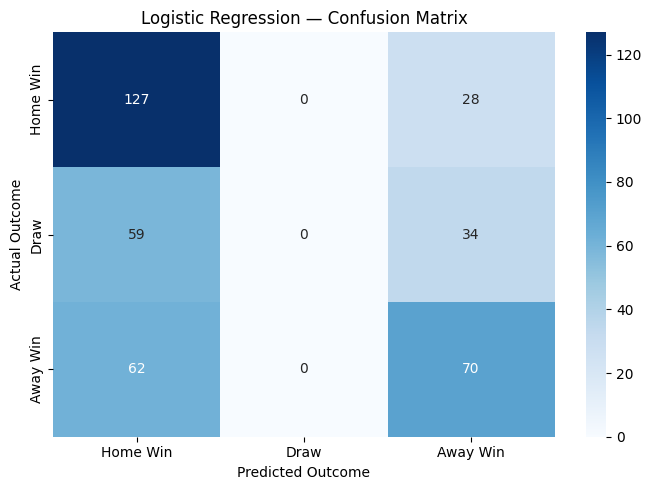

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Per-class performance
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        logistic_predictions,
        labels=["H", "D", "A"],
        target_names=["Home Win", "Draw", "Away Win"],
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_val,
    logistic_predictions,
    labels=["H", "D", "A"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Home Win", "Draw", "Away Win"],
    yticklabels=["Home Win", "Draw", "Away Win"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

In [ ]:
# Create a probability diagnostic dataframe
probability_analysis = pd.DataFrame(
    logistic_probabilities,
    columns=logistic_model.classes_
)

probability_analysis["actual_result"] = y_val.reset_index(drop=True)
probability_analysis["predicted_result"] = logistic_predictions

# --------------------------------------------------
# Predicted class distribution
# --------------------------------------------------

print("PREDICTED CLASS DISTRIBUTION")
print("=" * 40)

print(probability_analysis["predicted_result"].value_counts())

# --------------------------------------------------
# Average probabilities by actual outcome
# --------------------------------------------------

print("\nAVERAGE PREDICTED PROBABILITIES BY ACTUAL RESULT")
print("=" * 60)

print(
    probability_analysis
    .groupby("actual_result")[["A", "D", "H"]]
    .mean()
    .round(4)
)

# --------------------------------------------------
# Overall average probabilities
# --------------------------------------------------

print("\nOVERALL AVERAGE PREDICTED PROBABILITIES")
print("=" * 45)

print(
    probability_analysis[["A", "D", "H"]]
    .mean()
    .round(4)
)

# --------------------------------------------------
# Draw probability distribution
# --------------------------------------------------

print("\nDRAW PROBABILITY SUMMARY")
print("=" * 40)

print(
    probability_analysis["D"]
    .describe()
    .round(4)
)

PREDICTED CLASS DISTRIBUTION
predicted_result
H    248
A    132
Name: count, dtype: int64

AVERAGE PREDICTED PROBABILITIES BY ACTUAL RESULT
                    A       D       H
actual_result                        
A              0.4066  0.2390  0.3544
D              0.3103  0.2349  0.4548
H              0.2286  0.2204  0.5510

OVERALL AVERAGE PREDICTED PROBABILITIES
A    0.3104
D    0.2304
H    0.4592
dtype: float64

DRAW PROBABILITY SUMMARY
count    380.0000
mean       0.2304
std        0.0479
min        0.0681
25%        0.2066
50%        0.2403
75%        0.2646
max        0.3334
Name: D, dtype: float64


# Measure how close the model gets to predicting draws

In [ ]:
# Probability of draw
draw_prob = probability_analysis["D"]

# Highest probability among home and away wins
non_draw_max_prob = probability_analysis[["H", "A"]].max(axis=1)

# Gap between the best non-draw prediction and draw probability
draw_gap = non_draw_max_prob - draw_prob

print("DRAW PROBABILITY DIAGNOSTICS")
print("=" * 50)

print("\nAverage draw probability:")
print(f"Actual draws:     {draw_prob[y_val.reset_index(drop=True) == 'D'].mean():.4f}")
print(f"Non-draw matches: {draw_prob[y_val.reset_index(drop=True) != 'D'].mean():.4f}")

print("\nHow close was the draw probability to the leading outcome?")

for threshold in [0.02, 0.05, 0.10]:
    close_matches = (draw_gap <= threshold).sum()

    print(
        f"Draw within {threshold:.0%} of leading outcome: "
        f"{close_matches} matches ({close_matches / len(df) * 100:.2f}%)"
    )

print("\nMean probability gap:")
print(f"{draw_gap.mean():.4f}")

print("\nActual draw matches where draw was the second-highest probability:")
draw_matches = probability_analysis["actual_result"] == "D"

draw_second_place = (
    probability_analysis.loc[draw_matches, "D"]
    > probability_analysis.loc[draw_matches, ["H", "A"]].min(axis=1)
)

print(
    f"{draw_second_place.sum()} out of {draw_matches.sum()} actual draws"
)

DRAW PROBABILITY DIAGNOSTICS

Average draw probability:
Actual draws:     0.2349
Non-draw matches: 0.2289

How close was the draw probability to the leading outcome?
Draw within 2% of leading outcome: 0 matches (0.00%)
Draw within 5% of leading outcome: 1 matches (0.03%)
Draw within 10% of leading outcome: 18 matches (0.59%)

Mean probability gap:
0.3343

Actual draw matches where draw was the second-highest probability:
66 out of 93 actual draws


In [ ]:
n_val = len(probability_analysis)

print("CORRECTED DRAW DIAGNOSTICS")
print("=" * 45)

for threshold in [0.02, 0.05, 0.10]:
    close_matches = (draw_gap <= threshold).sum()

    print(
        f"Draw within {threshold:.0%} of leading outcome: "
        f"{close_matches}/{n_val} "
        f"({close_matches / n_val:.2%})"
    )

# Identify draws ranked exactly second
draw_second = (
    (probability_analysis["D"] < probability_analysis[["H", "A"]].max(axis=1))
    & (probability_analysis["D"] > probability_analysis[["H", "A"]].min(axis=1))
)

print("\nActual draws ranked second:")
print(
    f"{(draw_second & draw_matches).sum()} / {draw_matches.sum()}"
)

CORRECTED DRAW DIAGNOSTICS
Draw within 2% of leading outcome: 0/380 (0.00%)
Draw within 5% of leading outcome: 1/380 (0.26%)
Draw within 10% of leading outcome: 18/380 (4.74%)

Actual draws ranked second:
66 / 93


# Step 4.10.1 — Random Forest training

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Train on training data only
rf_model.fit(X_train, y_train)

# Generate validation predictions
rf_predictions = rf_model.predict(X_val)
rf_probabilities = rf_model.predict_proba(X_val)

print("Random Forest training completed.")
print("Number of trees:", rf_model.n_estimators)
print("Probability classes:", rf_model.classes_)
print("Validation predictions generated:", len(rf_predictions))

Random Forest training completed.
Number of trees: 500
Probability classes: ['A' 'D' 'H']
Validation predictions generated: 380


# Evaluate Random Forest

In [ ]:
# Random Forest validation accuracy
rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

# Log Loss
rf_log_loss = log_loss(
    y_val,
    rf_probabilities,
    labels=rf_model.classes_
)

# Multiclass Brier Score
classes = rf_model.classes_

y_val_onehot = pd.get_dummies(y_val).reindex(
    columns=classes,
    fill_value=0
).values

rf_brier_score = np.mean(
    np.sum(
        (rf_probabilities - y_val_onehot) ** 2,
        axis=1
    )
)

# Display results
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 45)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Log Loss:  {rf_log_loss:.4f}")
print(f"Brier Score: {rf_brier_score:.4f}")
print(f"Classes: {rf_model.classes_}")

RANDOM FOREST — VALIDATION RESULTS
Accuracy:  0.5184
Log Loss:  1.0080
Brier Score: 0.6048
Classes: ['A' 'D' 'H']


# Inspect Random Forest's predictions

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("RANDOM FOREST — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_val,
    rf_predictions,
    labels=["H", "D", "A"],
    target_names=["Home Win", "Draw", "Away Win"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
print("=" * 50)

rf_cm = confusion_matrix(
    y_val,
    rf_predictions,
    labels=["H", "D", "A"]
)

print(rf_cm)

RANDOM FOREST — CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Home Win       0.52      0.84      0.64       155
        Draw       0.20      0.02      0.04        93
    Away Win       0.55      0.49      0.52       132

    accuracy                           0.52       380
   macro avg       0.42      0.45      0.40       380
weighted avg       0.45      0.52      0.45       380


CONFUSION MATRIX
[[130   3  22]
 [ 60   2  31]
 [ 62   5  65]]


In [ ]:
# Random Forest feature importance

rf_feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
})

rf_feature_importance = rf_feature_importance.sort_values(
    by="importance",
    ascending=False
)

print("RANDOM FOREST — FEATURE IMPORTANCE")
print("=" * 50)

display(rf_feature_importance)

RANDOM FOREST — FEATURE IMPORTANCE


,feature,importance
0,elo_difference,0.225890
13,home_matches_played_before,0.099680
14,away_matches_played_before,0.097070
10,goals_scored_form_difference,0.070047
9,points_form_difference,0.069052
11,goals_conceded_form_difference,0.064621
2,home_goals_scored_last5,0.051658
7,away_goals_conceded_last5,0.051262
6,away_goals_scored_last5,0.050219
3,home_goals_conceded_last5,0.050013


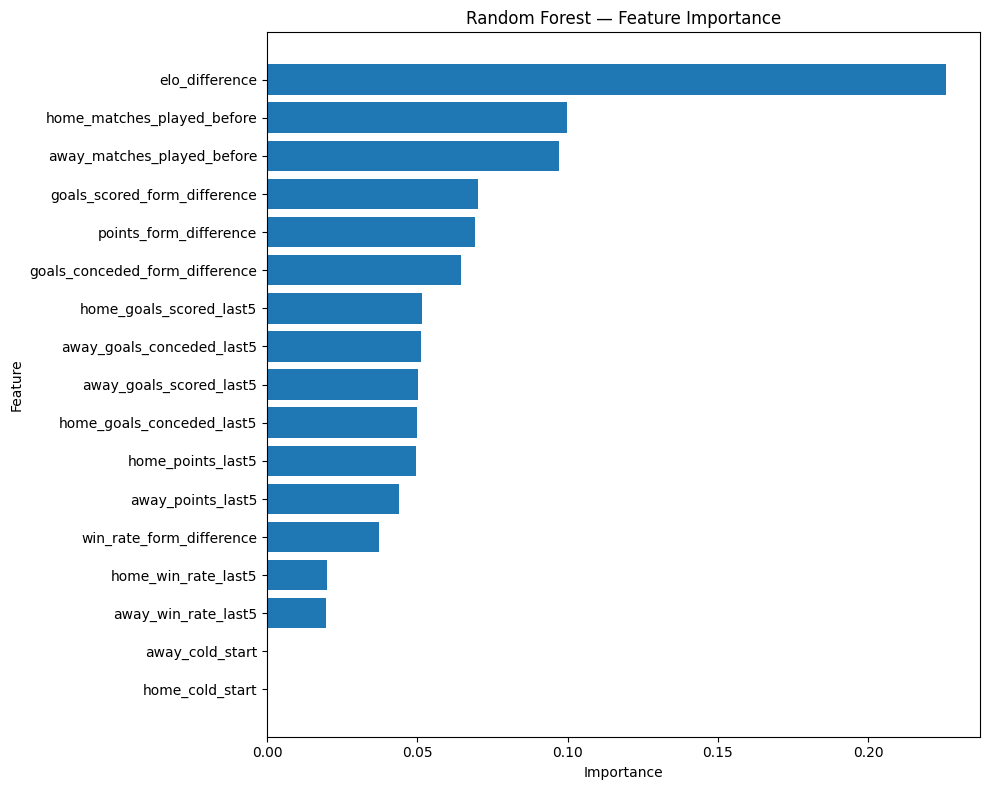

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.barh(
    rf_feature_importance["feature"],
    rf_feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest — Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Gradient Boosting model

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed.")
print("Iterations:", gb_model.n_iter_)
print("Classes:", gb_model.classes_)

Gradient Boosting training completed.
Iterations: 300
Classes: ['A' 'D' 'H']


In [ ]:
# Gradient Boosting validation predictions
gb_predictions = gb_model.predict(X_val)
gb_probabilities = gb_model.predict_proba(X_val)

# Accuracy
gb_accuracy = accuracy_score(
    y_val,
    gb_predictions
)

# Log Loss
gb_log_loss = log_loss(
    y_val,
    gb_probabilities,
    labels=gb_model.classes_
)

# Multiclass Brier Score
classes = gb_model.classes_

y_val_onehot = pd.get_dummies(y_val).reindex(
    columns=classes,
    fill_value=0
).values

gb_brier_score = np.mean(
    np.sum(
        (gb_probabilities - y_val_onehot) ** 2,
        axis=1
    )
)

# Display results
print("GRADIENT BOOSTING — VALIDATION RESULTS")
print("=" * 45)

print(f"Accuracy:  {gb_accuracy:.4f}")
print(f"Log Loss:  {gb_log_loss:.4f}")
print(f"Brier Score: {gb_brier_score:.4f}")
print(f"Classes: {gb_model.classes_}")

GRADIENT BOOSTING — VALIDATION RESULTS
Accuracy:  0.4763
Log Loss:  1.3561
Brier Score: 0.7478
Classes: ['A' 'D' 'H']


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("GRADIENT BOOSTING — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_val,
    gb_predictions,
    labels=["H", "D", "A"],
    target_names=["Home Win", "Draw", "Away Win"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
print("=" * 50)

gb_cm = confusion_matrix(
    y_val,
    gb_predictions,
    labels=["H", "D", "A"]
)

print(gb_cm)

GRADIENT BOOSTING — CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Home Win       0.50      0.79      0.61       155
        Draw       0.32      0.19      0.24        93
    Away Win       0.52      0.31      0.39       132

    accuracy                           0.48       380
   macro avg       0.44      0.43      0.41       380
weighted avg       0.46      0.48      0.44       380


CONFUSION MATRIX
[[122  14  19]
 [ 56  18  19]
 [ 66  25  41]]


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        0.4079,
        logistic_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    "Log Loss": [
        1.0809,
        logistic_log_loss,
        rf_log_loss,
        gb_log_loss
    ],
    "Brier Score": [
        0.6554,
        logistic_brier_score,
        rf_brier_score,
        gb_brier_score
    ]
})

model_comparison = model_comparison.sort_values(
    by="Log Loss",
    ascending=True
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Accuracy,Log Loss,Brier Score
0,Logistic Regression,0.5184,0.9946,0.5966
1,Random Forest,0.5184,1.0080,0.6048
2,Baseline,0.4079,1.0809,0.6554
3,Gradient Boosting,0.4763,1.3561,0.7478


# Probability calibration analysis

In [ ]:
# Logistic Regression probability analysis

lr_probability_df = pd.DataFrame(
    logistic_probabilities,
    columns=logistic_model.classes_
)

lr_probability_df["actual_result"] = y_val.values

print("AVERAGE PREDICTED PROBABILITIES BY ACTUAL RESULT")
print("=" * 60)

display(
    lr_probability_df.groupby("actual_result")[
        ["A", "D", "H"]
    ].mean().round(4)
)

print("\nACTUAL OUTCOME FREQUENCIES")
print("=" * 60)

display(
    y_val.value_counts(normalize=True)
    .sort_index()
    .round(4)
)

AVERAGE PREDICTED PROBABILITIES BY ACTUAL RESULT


,A,D,H
actual_result,,,
A,0.4066,0.2390,0.3544
D,0.3103,0.2349,0.4548
H,0.2286,0.2204,0.5510



ACTUAL OUTCOME FREQUENCIES


,proportion
match_result,
A,0.3474
D,0.2447
H,0.4079


# Build a probability calibration table

In [ ]:
# Logistic Regression probability calibration

calibration_results = []

for outcome in ["A", "D", "H"]:

    calibration_df = pd.DataFrame({
        "predicted_probability": lr_probability_df[outcome],
        "actual_outcome": (
            y_val == outcome
        ).astype(int)
    })

    calibration_df["probability_bin"] = pd.cut(
        calibration_df["predicted_probability"],
        bins=10,
        include_lowest=True
    )

    calibration_table = (
        calibration_df.groupby(
            "probability_bin",
            observed=True
        )
        .agg(
            matches=("actual_outcome", "count"),
            mean_predicted_probability=(
                "predicted_probability", "mean"
            ),
            actual_frequency=("actual_outcome", "mean")
        )
        .reset_index()
    )

    calibration_table["outcome"] = outcome

    calibration_results.append(calibration_table)

calibration_df_final = pd.concat(
    calibration_results,
    ignore_index=True
)

display(
    calibration_df_final.round(4)
)

,probability_bin,matches,mean_predicted_probability,actual_frequency,outcome
0,"(0.008390000000000002, 0.0972]",0,0.0633,NaN,A
1,"(0.0972, 0.184]",0,0.1420,NaN,A
2,"(0.184, 0.271]",0,0.2271,NaN,A
3,"(0.271, 0.358]",0,0.3157,NaN,A
4,"(0.358, 0.445]",0,0.3984,NaN,A
5,"(0.445, 0.532]",0,0.4860,NaN,A
6,"(0.532, 0.619]",0,0.5661,NaN,A
7,"(0.619, 0.705]",0,0.6620,NaN,A
8,"(0.705, 0.792]",0,0.7380,NaN,A
9,"(0.792, 0.879]",0,0.8353,NaN,A


In [ ]:
# Diagnose the calibration binning issue

for outcome in ["A", "D", "H"]:

    probabilities = lr_probability_df[outcome]

    actual = (y_val == outcome).astype(int)

    bins = pd.cut(
        probabilities,
        bins=10,
        include_lowest=True
    )

    diagnostic = pd.DataFrame({
        "probability": probabilities,
        "actual": actual,
        "bin": bins
    })

    print(f"\nOUTCOME: {outcome}")
    print("-" * 40)

    print("Total observations:", len(diagnostic))
    print("Non-missing probabilities:", probabilities.notna().sum())
    print("Non-missing bins:", bins.notna().sum())

    display(
        diagnostic.groupby("bin", observed=True)
        .agg(
            count=("actual", "size"),
            actual_frequency=("actual", "mean"),
            mean_probability=("probability", "mean")
        )
        .round(4)
    )


OUTCOME: A
----------------------------------------
Total observations: 760
Non-missing probabilities: 380
Non-missing bins: 380


,count,actual_frequency,mean_probability
bin,,,
"(0.008390000000000002, 0.0972]",55,NaN,0.0633
"(0.0972, 0.184]",59,NaN,0.1420
"(0.184, 0.271]",72,NaN,0.2271
"(0.271, 0.358]",55,NaN,0.3157
"(0.358, 0.445]",46,NaN,0.3984
"(0.445, 0.532]",36,NaN,0.4860
"(0.532, 0.619]",24,NaN,0.5661
"(0.619, 0.705]",22,NaN,0.6620
"(0.705, 0.792]",8,NaN,0.7380



OUTCOME: D
----------------------------------------
Total observations: 760
Non-missing probabilities: 380
Non-missing bins: 380


,count,actual_frequency,mean_probability
bin,,,
"(0.0669, 0.0947]",6,NaN,0.0795
"(0.0947, 0.121]",6,NaN,0.1086
"(0.121, 0.148]",11,NaN,0.1332
"(0.148, 0.174]",27,NaN,0.1628
"(0.174, 0.201]",37,NaN,0.1869
"(0.201, 0.227]",64,NaN,0.2147
"(0.227, 0.254]",94,NaN,0.2418
"(0.254, 0.28]",89,NaN,0.2658
"(0.28, 0.307]",41,NaN,0.2912



OUTCOME: H
----------------------------------------
Total observations: 760
Non-missing probabilities: 380
Non-missing bins: 380


,count,actual_frequency,mean_probability
bin,,,
"(0.0419, 0.131]",24,NaN,0.0928
"(0.131, 0.218]",34,NaN,0.1772
"(0.218, 0.305]",46,NaN,0.2621
"(0.305, 0.391]",44,NaN,0.3496
"(0.391, 0.478]",53,NaN,0.4356
"(0.478, 0.565]",55,NaN,0.5192
"(0.565, 0.652]",44,NaN,0.6078
"(0.652, 0.739]",37,NaN,0.7011
"(0.739, 0.826]",30,NaN,0.7728


In [ ]:
# Corrected probability calibration diagnostic

for outcome in ["A", "D", "H"]:

    probabilities = lr_probability_df[outcome].reset_index(drop=True)

    actual = (
        (y_val.reset_index(drop=True) == outcome)
        .astype(int)
    )

    calibration_diagnostic = pd.DataFrame({
        "probability": probabilities.to_numpy(),
        "actual": actual.to_numpy()
    })

    calibration_diagnostic["bin"] = pd.cut(
        calibration_diagnostic["probability"],
        bins=10,
        include_lowest=True
    )

    print(f"\nOUTCOME: {outcome}")
    print("-" * 40)

    display(
        calibration_diagnostic.groupby(
            "bin",
            observed=True
        )
        .agg(
            count=("actual", "size"),
            actual_frequency=("actual", "mean"),
            mean_probability=("probability", "mean")
        )
        .round(4)
    )


OUTCOME: A
----------------------------------------


,count,actual_frequency,mean_probability
bin,,,
"(0.008390000000000002, 0.0972]",55,0.0727,0.0633
"(0.0972, 0.184]",59,0.2203,0.1420
"(0.184, 0.271]",72,0.2639,0.2271
"(0.271, 0.358]",55,0.4000,0.3157
"(0.358, 0.445]",46,0.4783,0.3984
"(0.445, 0.532]",36,0.3889,0.4860
"(0.532, 0.619]",24,0.6667,0.5661
"(0.619, 0.705]",22,0.5455,0.6620
"(0.705, 0.792]",8,1.0000,0.7380



OUTCOME: D
----------------------------------------


,count,actual_frequency,mean_probability
bin,,,
"(0.0669, 0.0947]",6,0.0000,0.0795
"(0.0947, 0.121]",6,0.0000,0.1086
"(0.121, 0.148]",11,0.1818,0.1332
"(0.148, 0.174]",27,0.3333,0.1628
"(0.174, 0.201]",37,0.3243,0.1869
"(0.201, 0.227]",64,0.1562,0.2147
"(0.227, 0.254]",94,0.2340,0.2418
"(0.254, 0.28]",89,0.2809,0.2658
"(0.28, 0.307]",41,0.3171,0.2912



OUTCOME: H
----------------------------------------


,count,actual_frequency,mean_probability
bin,,,
"(0.0419, 0.131]",24,0.1250,0.0928
"(0.131, 0.218]",34,0.0882,0.1772
"(0.218, 0.305]",46,0.3043,0.2621
"(0.305, 0.391]",44,0.3409,0.3496
"(0.391, 0.478]",53,0.3396,0.4356
"(0.478, 0.565]",55,0.4909,0.5192
"(0.565, 0.652]",44,0.5227,0.6078
"(0.652, 0.739]",37,0.5676,0.7011
"(0.739, 0.826]",30,0.6333,0.7728


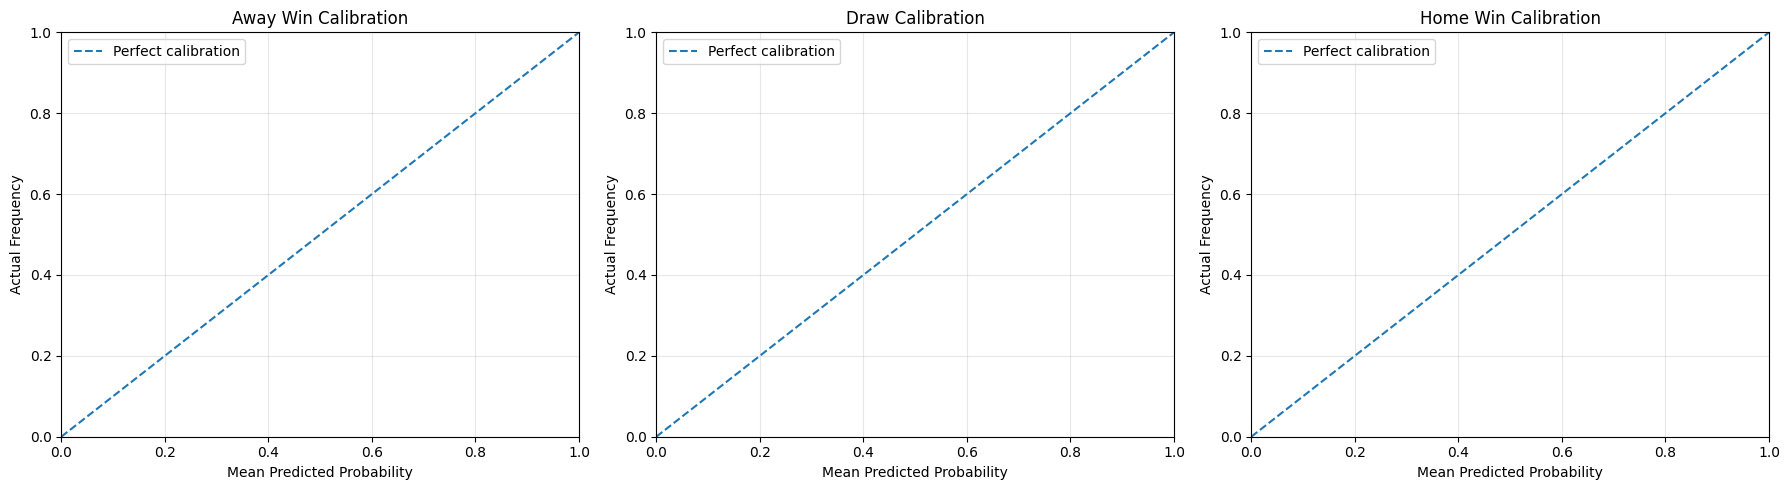

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

outcomes = ["A", "D", "H"]
titles = ["Away Win Calibration", "Draw Calibration", "Home Win Calibration"]

for ax, outcome, title in zip(axes, outcomes, titles):

    outcome_data = calibration_df_final[
        calibration_df_final["outcome"] == outcome
    ]

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    ax.scatter(
        outcome_data["mean_predicted_probability"],
        outcome_data["actual_frequency"],
        s=60
    )

    ax.plot(
        outcome_data["mean_predicted_probability"],
        outcome_data["actual_frequency"]
    )

    ax.set_title(title)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Actual Frequency")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
calibration_df_final = []

for outcome in ["A", "D", "H"]:

    probabilities = lr_probability_df[outcome].reset_index(drop=True)

    actual = (
        y_val.reset_index(drop=True) == outcome
    ).astype(int)

    diagnostic = pd.DataFrame({
        "probability": probabilities,
        "actual": actual
    })

    diagnostic["bin"] = pd.cut(
        diagnostic["probability"],
        bins=10,
        include_lowest=True
    )

    grouped = diagnostic.groupby(
        "bin",
        observed=True
    ).agg(
        count=("actual", "size"),
        actual_frequency=("actual", "mean"),
        mean_predicted_probability=("probability", "mean")
    ).reset_index()

    grouped["outcome"] = outcome

    calibration_df_final.append(grouped)

calibration_df_final = pd.concat(
    calibration_df_final,
    ignore_index=True
)

calibration_df_final.head(10)

,bin,count,actual_frequency,mean_predicted_probability,outcome
0,"(0.008390000000000002, 0.0972]",55,0.072727,0.063280,A
1,"(0.0972, 0.184]",59,0.220339,0.142006,A
2,"(0.184, 0.271]",72,0.263889,0.227106,A
3,"(0.271, 0.358]",55,0.400000,0.315679,A
4,"(0.358, 0.445]",46,0.478261,0.398402,A
5,"(0.445, 0.532]",36,0.388889,0.485965,A
6,"(0.532, 0.619]",24,0.666667,0.566147,A
7,"(0.619, 0.705]",22,0.545455,0.661998,A
8,"(0.705, 0.792]",8,1.000000,0.737991,A
9,"(0.792, 0.879]",3,0.666667,0.835310,A


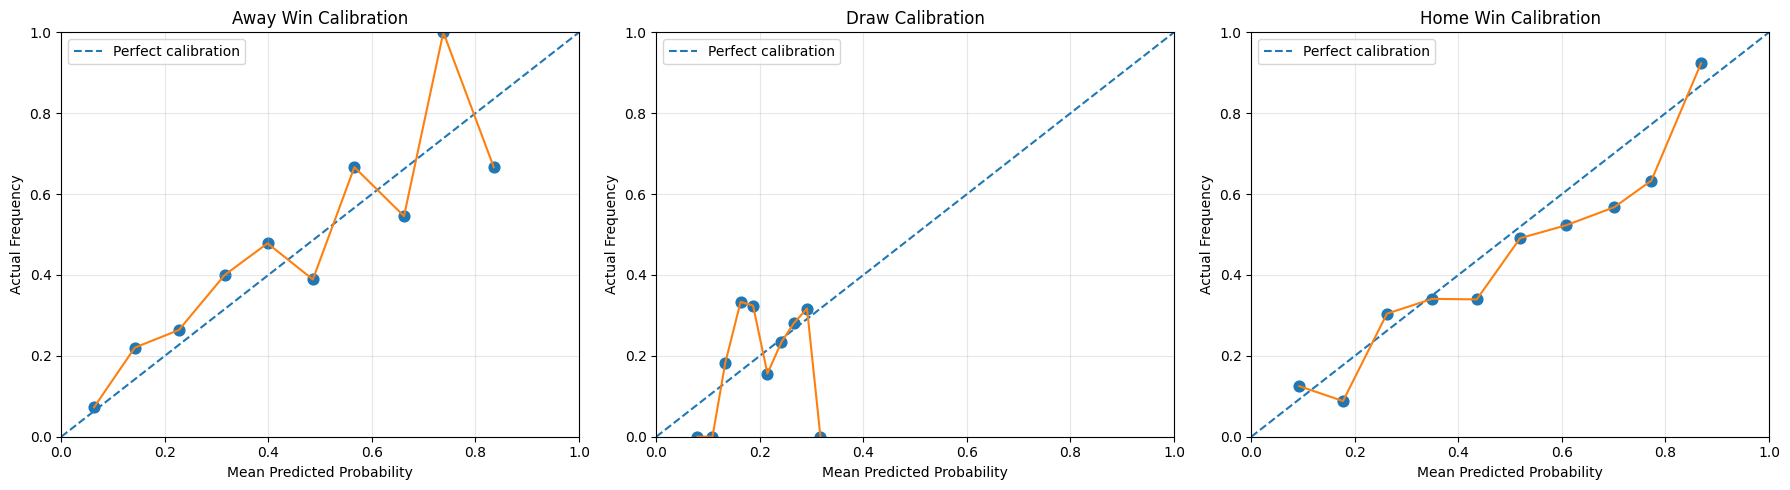

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

outcomes = ["A", "D", "H"]
titles = ["Away Win Calibration", "Draw Calibration", "Home Win Calibration"]

for ax, outcome, title in zip(axes, outcomes, titles):

    outcome_data = calibration_df_final[
        calibration_df_final["outcome"] == outcome
    ]

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    ax.scatter(
        outcome_data["mean_predicted_probability"],
        outcome_data["actual_frequency"],
        s=60
    )

    ax.plot(
        outcome_data["mean_predicted_probability"],
        outcome_data["actual_frequency"]
    )

    ax.set_title(title)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Actual Frequency")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving england-premier-league-matches-2026-to-2027-stats.csv to england-premier-league-matches-2026-to-2027-stats.csv


In [ ]:
import pandas as pd

fixtures_df = pd.read_csv(
    "england-premier-league-matches-2026-to-2027-stats.csv"
)

print("Dataset shape:", fixtures_df.shape)
print("Number of matches:", len(fixtures_df))

display(fixtures_df.head())

Dataset shape: (380, 66)
Number of matches: 380


,timestamp,date_GMT,status,attendance,home_team_name,away_team_name,referee,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),...,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no,stadium_name
0,1787338800,Aug 21 2026 - 7:00pm,complete,60098.0,Arsenal,Coventry City,NaN,1,0.0,0.0,...,1.21,6.50,11.50,1.13,1.63,2.29,4.00,2.19,1.62,Emirates Stadium
1,1787398200,Aug 22 2026 - 11:30am,complete,24470.0,Hull City,Manchester United,NaN,1,0.0,0.0,...,8.50,5.00,1.33,1.13,1.60,2.46,4.25,1.83,1.87,KCOM Stadium
2,1787407200,Aug 22 2026 - 2:00pm,complete,51820.0,Everton,Crystal Palace,NaN,1,0.0,0.0,...,2.11,3.36,3.28,1.31,2.00,3.26,6.75,1.75,2.05,NaN
3,1787407200,Aug 22 2026 - 2:00pm,complete,30739.0,Nottingham Forest,Leeds United,NaN,1,0.0,0.0,...,2.32,3.35,3.10,1.34,2.11,3.48,7.00,1.75,2.10,The City Ground
4,1787407200,Aug 22 2026 - 2:00pm,complete,29669.0,Ipswich Town,Sunderland,NaN,1,0.0,0.0,...,2.70,3.17,2.66,1.34,2.15,3.55,8.00,1.73,1.87,Portman Road Stadium


In [ ]:
upcoming_fixtures = fixtures_df[
    fixtures_df["status"] != "complete"
].copy()

upcoming_fixtures = upcoming_fixtures[
    [
        "timestamp",
        "date_GMT",
        "Game Week",
        "home_team_name",
        "away_team_name",
        "status"
    ]
].sort_values("timestamp")

print("Upcoming fixtures:", len(upcoming_fixtures))

display(upcoming_fixtures.head(15))

Upcoming fixtures: 280


,timestamp,date_GMT,Game Week,home_team_name,away_team_name,status
100,1795264200,Nov 21 2026 - 12:30pm,11,Manchester City,Fulham,incomplete
101,1795273200,Nov 21 2026 - 3:00pm,11,Coventry City,Crystal Palace,incomplete
102,1795273200,Nov 21 2026 - 3:00pm,11,Tottenham Hotspur,Ipswich Town,incomplete
103,1795273200,Nov 21 2026 - 3:00pm,11,AFC Bournemouth,Nottingham Forest,incomplete
104,1795273200,Nov 21 2026 - 3:00pm,11,Chelsea,Leeds United,incomplete
105,1795273200,Nov 21 2026 - 3:00pm,11,Aston Villa,Sunderland,incomplete
106,1795282200,Nov 21 2026 - 5:30pm,11,Newcastle United,Arsenal,incomplete
107,1795356000,Nov 22 2026 - 2:00pm,11,Hull City,Brighton & Hove Albion,incomplete
108,1795365000,Nov 22 2026 - 4:30pm,11,Liverpool,Manchester United,incomplete
109,1795464000,Nov 23 2026 - 8:00pm,11,Brentford,Everton,incomplete


# Audit the remaining fixture statuses

In [ ]:
print("Fixture status distribution:")
display(fixtures_df["status"].value_counts())

print("\nUpcoming fixtures by gameweek:")
display(
    upcoming_fixtures.groupby("Game Week")
    .size()
    .reset_index(name="fixtures_count")
    .sort_values("Game Week")
)

Fixture status distribution:


,count
status,
incomplete,279
complete,100
suspended,1



Upcoming fixtures by gameweek:


,Game Week,fixtures_count
0,11,10
1,12,10
2,13,10
3,14,10
4,15,10
5,16,10
6,17,10
7,18,10
8,19,10
9,20,10


In [ ]:
prediction_fixtures = fixtures_df[
    fixtures_df["status"] == "incomplete"
].copy()

prediction_fixtures = prediction_fixtures[
    [
        "timestamp",
        "date_GMT",
        "Game Week",
        "home_team_name",
        "away_team_name",
        "status"
    ]
].sort_values("timestamp").reset_index(drop=True)

print("Fixtures ready for prediction:", len(prediction_fixtures))

display(prediction_fixtures.head(10))

Fixtures ready for prediction: 279


,timestamp,date_GMT,Game Week,home_team_name,away_team_name,status
0,1795264200,Nov 21 2026 - 12:30pm,11,Manchester City,Fulham,incomplete
1,1795273200,Nov 21 2026 - 3:00pm,11,Coventry City,Crystal Palace,incomplete
2,1795273200,Nov 21 2026 - 3:00pm,11,Tottenham Hotspur,Ipswich Town,incomplete
3,1795273200,Nov 21 2026 - 3:00pm,11,AFC Bournemouth,Nottingham Forest,incomplete
4,1795273200,Nov 21 2026 - 3:00pm,11,Chelsea,Leeds United,incomplete
5,1795273200,Nov 21 2026 - 3:00pm,11,Aston Villa,Sunderland,incomplete
6,1795282200,Nov 21 2026 - 5:30pm,11,Newcastle United,Arsenal,incomplete
7,1795356000,Nov 22 2026 - 2:00pm,11,Hull City,Brighton & Hove Albion,incomplete
8,1795365000,Nov 22 2026 - 4:30pm,11,Liverpool,Manchester United,incomplete
9,1795464000,Nov 23 2026 - 8:00pm,11,Brentford,Everton,incomplete


In [ ]:
import os

print("Files currently available:")
print(os.listdir("/content"))

Files currently available:
['.config', 'england-premier-league-matches-2026-to-2027-stats.csv', 'epl_model_dataset.csv', 'sample_data']


In [ ]:
historical_model_df = pd.read_csv(
    "/content/epl_model_dataset.csv"
)

print("Historical dataset shape:", historical_model_df.shape)

display(historical_model_df.head())

Historical dataset shape: (3040, 22)


,timestamp,season,home_team,away_team,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,...,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start,match_result
0,1533927600,2018/19,Manchester United,Leicester City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
1,1533987000,2018/19,Newcastle United,Tottenham Hotspur,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
2,1533996000,2018/19,Fulham,Crystal Palace,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
3,1533996000,2018/19,AFC Bournemouth,Cardiff City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
4,1533996000,2018/19,Watford,Brighton & Hove Albion,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H


In [ ]:
feature_columns = [
    "elo_difference",
    "home_points_last5",
    "home_goals_scored_last5",
    "home_goals_conceded_last5",
    "home_win_rate_last5",
    "away_points_last5",
    "away_goals_scored_last5",
    "away_goals_conceded_last5",
    "away_win_rate_last5",
    "points_form_difference",
    "goals_scored_form_difference",
    "goals_conceded_form_difference",
    "win_rate_form_difference",
    "home_matches_played_before",
    "away_matches_played_before",
    "home_cold_start",
    "away_cold_start"
]

target_column = "match_result"

print("Number of features:", len(feature_columns))
print("\nMissing feature columns:")
print(set(feature_columns) - set(historical_model_df.columns))

print("\nTarget classes:")
print(historical_model_df[target_column].value_counts())

print("\nTarget missing values:")
print(historical_model_df[target_column].isna().sum())

Number of features: 17

Missing feature columns:
set()

Target classes:
match_result
H    1336
A    1004
D     700
Name: count, dtype: int64

Target missing values:
0


In [ ]:
print("Historical date range:")
print(
    pd.to_datetime(historical_model_df["timestamp"], unit="s").min(),
    "to",
    pd.to_datetime(historical_model_df["timestamp"], unit="s").max()
)

print("\nSeasons covered:")
print(historical_model_df["season"].unique())

print("\nNumber of unique teams:")
teams = set(historical_model_df["home_team"]) | set(historical_model_df["away_team"])
print(len(teams))

print("\nTeams:")
print(sorted(teams))

print("\nMatches per season:")
print(historical_model_df.groupby("season").size())

Historical date range:
2018-08-10 19:00:00 to 2026-05-24 15:00:00

Seasons covered:
['2018/19' '2019/20' '2020/21' '2021/22' '2022/23' '2023/24' '2024/25'
 '2025/26']

Number of unique teams:
30

Teams:
['AFC Bournemouth', 'Arsenal', 'Aston Villa', 'Brentford', 'Brighton & Hove Albion', 'Burnley', 'Cardiff City', 'Chelsea', 'Crystal Palace', 'Everton', 'Fulham', 'Huddersfield Town', 'Ipswich Town', 'Leeds United', 'Leicester City', 'Liverpool', 'Luton Town', 'Manchester City', 'Manchester United', 'Newcastle United', 'Norwich City', 'Nottingham Forest', 'Sheffield United', 'Southampton', 'Sunderland', 'Tottenham Hotspur', 'Watford', 'West Bromwich Albion', 'West Ham United', 'Wolverhampton Wanderers']

Matches per season:
season
2018/19    380
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    380
dtype: int64


In [ ]:
historical_teams = (
    set(historical_model_df["home_team"]) |
    set(historical_model_df["away_team"])
)

current_teams = (
    set(fixtures_df["home_team_name"]) |
    set(fixtures_df["away_team_name"])
)

print("Teams in historical dataset:", len(historical_teams))
print("Teams in 2026/27 fixtures:", len(current_teams))

print("\nTeams with no historical coverage:")
print(sorted(current_teams - historical_teams))

print("\nTeams no longer appearing in current fixtures:")
print(sorted(historical_teams - current_teams))

Teams in historical dataset: 30
Teams in 2026/27 fixtures: 20

Teams with no historical coverage:
['Coventry City', 'Hull City']

Teams no longer appearing in current fixtures:
['Burnley', 'Cardiff City', 'Huddersfield Town', 'Leicester City', 'Luton Town', 'Norwich City', 'Sheffield United', 'Southampton', 'Watford', 'West Bromwich Albion', 'West Ham United', 'Wolverhampton Wanderers']


In [ ]:
completed_matches = fixtures_df[
    fixtures_df["status"] == "complete"
].copy()

print("Completed matches:", len(completed_matches))

print("\nAvailable columns:")
print(completed_matches.columns.tolist())

print("\nSample completed matches:")
display(completed_matches.head(5))

Completed matches: 100

Available columns:
['timestamp', 'date_GMT', 'status', 'attendance', 'home_team_name', 'away_team_name', 'referee', 'Game Week', 'Pre-Match PPG (Home)', 'Pre-Match PPG (Away)', 'home_ppg', 'away_ppg', 'home_team_goal_count', 'away_team_goal_count', 'total_goal_count', 'total_goals_at_half_time', 'home_team_goal_count_half_time', 'away_team_goal_count_half_time', 'home_team_goal_timings', 'away_team_goal_timings', 'home_team_corner_count', 'away_team_corner_count', 'home_team_yellow_cards', 'home_team_red_cards', 'away_team_yellow_cards', 'away_team_red_cards', 'home_team_first_half_cards', 'home_team_second_half_cards', 'away_team_first_half_cards', 'away_team_second_half_cards', 'home_team_shots', 'away_team_shots', 'home_team_shots_on_target', 'away_team_shots_on_target', 'home_team_shots_off_target', 'away_team_shots_off_target', 'home_team_fouls', 'away_team_fouls', 'home_team_possession', 'away_team_possession', 'Home Team Pre-Match xG', 'Away Team Pre-Matc

,timestamp,date_GMT,status,attendance,home_team_name,away_team_name,referee,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),...,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no,stadium_name
0,1787338800,Aug 21 2026 - 7:00pm,complete,60098.0,Arsenal,Coventry City,NaN,1,0.0,0.0,...,1.21,6.50,11.50,1.13,1.63,2.29,4.00,2.19,1.62,Emirates Stadium
1,1787398200,Aug 22 2026 - 11:30am,complete,24470.0,Hull City,Manchester United,NaN,1,0.0,0.0,...,8.50,5.00,1.33,1.13,1.60,2.46,4.25,1.83,1.87,KCOM Stadium
2,1787407200,Aug 22 2026 - 2:00pm,complete,51820.0,Everton,Crystal Palace,NaN,1,0.0,0.0,...,2.11,3.36,3.28,1.31,2.00,3.26,6.75,1.75,2.05,NaN
3,1787407200,Aug 22 2026 - 2:00pm,complete,30739.0,Nottingham Forest,Leeds United,NaN,1,0.0,0.0,...,2.32,3.35,3.10,1.34,2.11,3.48,7.00,1.75,2.10,The City Ground
4,1787407200,Aug 22 2026 - 2:00pm,complete,29669.0,Ipswich Town,Sunderland,NaN,1,0.0,0.0,...,2.70,3.17,2.66,1.34,2.15,3.55,8.00,1.73,1.87,Portman Road Stadium


In [ ]:
completed_matches = completed_matches.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Missing home scores:",
      completed_matches["home_team_goal_count"].isna().sum())

print("Missing away scores:",
      completed_matches["away_team_goal_count"].isna().sum())

print("\nFirst completed matches:")
display(
    completed_matches[
        [
            "timestamp",
            "Game Week",
            "home_team_name",
            "away_team_name",
            "home_team_goal_count",
            "away_team_goal_count"
        ]
    ].head(10)
)

print("\nLatest completed matches:")
display(
    completed_matches[
        [
            "timestamp",
            "Game Week",
            "home_team_name",
            "away_team_name",
            "home_team_goal_count",
            "away_team_goal_count"
        ]
    ].tail(10)
)

Missing home scores: 0
Missing away scores: 0

First completed matches:


,timestamp,Game Week,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count
0,1787338800,1,Arsenal,Coventry City,3,0
1,1787398200,1,Hull City,Manchester United,2,0
2,1787407200,1,Everton,Crystal Palace,2,0
3,1787407200,1,Nottingham Forest,Leeds United,0,1
4,1787407200,1,Ipswich Town,Sunderland,2,1
5,1787416200,1,Brentford,Tottenham Hotspur,3,0
6,1787490000,1,Brighton & Hove Albion,Aston Villa,4,0
7,1787490000,1,Manchester City,AFC Bournemouth,2,1
8,1787499000,1,Newcastle United,Liverpool,2,2
9,1787598000,1,Fulham,Chelsea,2,3



Latest completed matches:


,timestamp,Game Week,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count
90,1793995200,10,Everton,Coventry City,3,1
91,1794054600,10,Leeds United,Tottenham Hotspur,1,0
92,1794063600,10,Fulham,Newcastle United,1,1
93,1794063600,10,Arsenal,Hull City,1,0
94,1794072600,10,Nottingham Forest,Manchester City,3,1
95,1794146400,10,Brighton & Hove Albion,Brentford,2,0
96,1794146400,10,Sunderland,Chelsea,1,0
97,1794146400,10,Crystal Palace,Liverpool,1,3
98,1794146400,10,Ipswich Town,AFC Bournemouth,1,2
99,1794155400,10,Manchester United,Aston Villa,4,4


In [ ]:
team_match_counts = pd.concat([
    completed_matches["home_team_name"],
    completed_matches["away_team_name"]
]).value_counts().sort_index()

print("Teams represented in completed matches:", len(team_match_counts))

display(
    team_match_counts.rename("matches_played")
    .reset_index()
    .rename(columns={"index": "team"})
)

print("\nTotal team appearances:", team_match_counts.sum())

Teams represented in completed matches: 20


,team,matches_played
0,AFC Bournemouth,10
1,Arsenal,10
2,Aston Villa,10
3,Brentford,10
4,Brighton & Hove Albion,10
5,Chelsea,10
6,Coventry City,10
7,Crystal Palace,10
8,Everton,10
9,Fulham,10



Total team appearances: 200


In [ ]:
current_season_results = completed_matches[
    [
        "timestamp",
        "home_team_name",
        "away_team_name",
        "home_team_goal_count",
        "away_team_goal_count"
    ]
].copy()

current_season_results = current_season_results.rename(
    columns={
        "home_team_name": "home_team",
        "away_team_name": "away_team",
        "home_team_goal_count": "home_goals",
        "away_team_goal_count": "away_goals"
    }
)

current_season_results["match_result"] = np.select(
    [
        current_season_results["home_goals"] > current_season_results["away_goals"],
        current_season_results["home_goals"] < current_season_results["away_goals"]
    ],
    ["H", "A"],
    default="D"
)

current_season_results = current_season_results.sort_values(
    "timestamp"
).reset_index(drop=True)

display(current_season_results.head(10))

print("\nOutcome distribution:")
print(current_season_results["match_result"].value_counts())

print("\nTotal matches:", len(current_season_results))

,timestamp,home_team,away_team,home_goals,away_goals,match_result
0,1787338800,Arsenal,Coventry City,3,0,H
1,1787398200,Hull City,Manchester United,2,0,H
2,1787407200,Everton,Crystal Palace,2,0,H
3,1787407200,Nottingham Forest,Leeds United,0,1,A
4,1787407200,Ipswich Town,Sunderland,2,1,H
5,1787416200,Brentford,Tottenham Hotspur,3,0,H
6,1787490000,Brighton & Hove Albion,Aston Villa,4,0,H
7,1787490000,Manchester City,AFC Bournemouth,2,1,H
8,1787499000,Newcastle United,Liverpool,2,2,D
9,1787598000,Fulham,Chelsea,2,3,A



Outcome distribution:
match_result
H    42
A    31
D    27
Name: count, dtype: int64

Total matches: 100


# Prepare match-level information for Elo and form calculations

In [ ]:
current_season_results["home_points"] = np.select(
    [
        current_season_results["match_result"] == "H",
        current_season_results["match_result"] == "D"
    ],
    [3, 1],
    default=0
)

current_season_results["away_points"] = np.select(
    [
        current_season_results["match_result"] == "A",
        current_season_results["match_result"] == "D"
    ],
    [3, 1],
    default=0
)

current_season_results["home_goal_difference"] = (
    current_season_results["home_goals"] -
    current_season_results["away_goals"]
)

current_season_results["away_goal_difference"] = (
    current_season_results["away_goals"] -
    current_season_results["home_goals"]
)

display(
    current_season_results[
        [
            "home_team",
            "away_team",
            "home_goals",
            "away_goals",
            "match_result",
            "home_points",
            "away_points",
            "home_goal_difference",
            "away_goal_difference"
        ]
    ].head(10)
)

,home_team,away_team,home_goals,away_goals,match_result,home_points,away_points,home_goal_difference,away_goal_difference
0,Arsenal,Coventry City,3,0,H,3,0,3,-3
1,Hull City,Manchester United,2,0,H,3,0,2,-2
2,Everton,Crystal Palace,2,0,H,3,0,2,-2
3,Nottingham Forest,Leeds United,0,1,A,0,3,-1,1
4,Ipswich Town,Sunderland,2,1,H,3,0,1,-1
5,Brentford,Tottenham Hotspur,3,0,H,3,0,3,-3
6,Brighton & Hove Albion,Aston Villa,4,0,H,3,0,4,-4
7,Manchester City,AFC Bournemouth,2,1,H,3,0,1,-1
8,Newcastle United,Liverpool,2,2,D,1,1,0,0
9,Fulham,Chelsea,2,3,A,0,3,-1,1


# Initialize the current-season Elo engine

In [ ]:
INITIAL_ELO = 1500
K_FACTOR = 20
HOME_ADVANTAGE_ELO = 60

current_teams = sorted(
    set(current_season_results["home_team"]) |
    set(current_season_results["away_team"])
)

current_elo = {
    team: INITIAL_ELO
    for team in current_teams
}

print("Teams initialized:", len(current_elo))
print("Initial Elo:", INITIAL_ELO)

display(
    pd.DataFrame({
        "team": list(current_elo.keys()),
        "elo_rating": list(current_elo.values())
    })
)

Teams initialized: 20
Initial Elo: 1500


,team,elo_rating
0,AFC Bournemouth,1500
1,Arsenal,1500
2,Aston Villa,1500
3,Brentford,1500
4,Brighton & Hove Albion,1500
5,Chelsea,1500
6,Coventry City,1500
7,Crystal Palace,1500
8,Everton,1500
9,Fulham,1500


# Build the sequential Elo update engine

In [ ]:
import numpy as np

ELO_SCALE = 400

def calculate_expected_score(rating_a, rating_b):
    return 1 / (1 + 10 ** ((rating_b - rating_a) / ELO_SCALE))


current_elo = {
    team: INITIAL_ELO
    for team in current_teams
}

elo_history = []

# Process matches chronologically.
# Matches with the same timestamp are treated simultaneously.
for timestamp, match_group in current_season_results.groupby("timestamp", sort=True):

    rating_updates = {}

    # Calculate all updates using ratings available before this kickoff
    for _, match in match_group.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        home_rating = current_elo[home_team]
        away_rating = current_elo[away_team]

        expected_home = calculate_expected_score(
            home_rating + HOME_ADVANTAGE_ELO,
            away_rating
        )

        expected_away = 1 - expected_home

        if match["match_result"] == "H":
            actual_home = 1
            actual_away = 0

        elif match["match_result"] == "A":
            actual_home = 0
            actual_away = 1

        else:
            actual_home = 0.5
            actual_away = 0.5

        home_change = K_FACTOR * (actual_home - expected_home)
        away_change = K_FACTOR * (actual_away - expected_away)

        rating_updates[home_team] = (
            rating_updates.get(home_team, 0) + home_change
        )

        rating_updates[away_team] = (
            rating_updates.get(away_team, 0) + away_change
        )

    # Apply updates only after all matches at this timestamp are processed
    for team, change in rating_updates.items():
        current_elo[team] += change

    # Record updated ratings
    for team, rating in current_elo.items():
        elo_history.append({
            "timestamp": timestamp,
            "team": team,
            "elo_rating": rating
        })

current_elo_df = (
    pd.DataFrame(elo_history)
    .sort_values(["timestamp", "team"])
    .reset_index(drop=True)
)

print("Elo engine completed.")
print("Teams:", len(current_elo))
print("Matches processed:", len(current_season_results))

print("\nFinal current-season Elo ratings:")
display(
    pd.DataFrame({
        "team": list(current_elo.keys()),
        "elo_rating": list(current_elo.values())
    })
    .sort_values("elo_rating", ascending=False)
    .reset_index(drop=True)
)

Elo engine completed.
Teams: 20
Matches processed: 100

Final current-season Elo ratings:


,team,elo_rating
0,Arsenal,1572.215969
1,Brighton & Hove Albion,1547.977853
2,Manchester City,1529.505157
3,Liverpool,1528.603638
4,Everton,1517.936046
5,AFC Bournemouth,1512.984884
6,Brentford,1507.623641
7,Leeds United,1506.778968
8,Chelsea,1506.060305
9,Aston Villa,1503.832897


# Calculate current team form

In [ ]:
# Convert each match into a team-level record for both sides

home_form = current_season_results[
    [
        "timestamp",
        "home_team",
        "home_goals",
        "away_goals",
        "home_points",
        "match_result"
    ]
].copy()

home_form = home_form.rename(columns={
    "home_team": "team",
    "home_goals": "goals_scored",
    "away_goals": "goals_conceded",
    "home_points": "points"
})

home_form["win"] = (home_form["match_result"] == "H").astype(int)


away_form = current_season_results[
    [
        "timestamp",
        "away_team",
        "away_goals",
        "home_goals",
        "away_points",
        "match_result"
    ]
].copy()

away_form = away_form.rename(columns={
    "away_team": "team",
    "away_goals": "goals_scored",
    "home_goals": "goals_conceded",
    "away_points": "points"
})

away_form["win"] = (away_form["match_result"] == "A").astype(int)


# Combine home and away performances
team_match_form = pd.concat(
    [home_form, away_form],
    ignore_index=True
)

team_match_form = team_match_form.sort_values(
    ["team", "timestamp"]
).reset_index(drop=True)


# Calculate each team's rolling last-5 form
team_match_form["points_last5"] = (
    team_match_form.groupby("team")["points"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

team_match_form["goals_scored_last5"] = (
    team_match_form.groupby("team")["goals_scored"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

team_match_form["goals_conceded_last5"] = (
    team_match_form.groupby("team")["goals_conceded"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

team_match_form["win_rate_last5"] = (
    team_match_form.groupby("team")["win"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)


print("Team match form records:", len(team_match_form))
print("Unique teams:", team_match_form["team"].nunique())

display(team_match_form.head(15))

Team match form records: 200
Unique teams: 20


,timestamp,team,goals_scored,goals_conceded,points,match_result,win,points_last5,goals_scored_last5,goals_conceded_last5,win_rate_last5
0,1787490000,AFC Bournemouth,1,2,0,H,0,NaN,NaN,NaN,NaN
1,1788012000,AFC Bournemouth,1,1,1,D,0,0.0,1.000000,2.000000,0.0
2,1788607800,AFC Bournemouth,2,2,1,D,0,1.0,1.000000,1.500000,0.0
3,1789221600,AFC Bournemouth,2,2,1,D,0,2.0,1.333333,1.666667,0.0
4,1789909200,AFC Bournemouth,0,1,0,A,0,3.0,1.500000,1.750000,0.0
5,1791640800,AFC Bournemouth,1,5,0,H,0,3.0,1.200000,1.600000,0.0
6,1792328400,AFC Bournemouth,2,0,3,H,1,3.0,1.200000,2.200000,0.0
7,1792936800,AFC Bournemouth,3,0,3,A,1,5.0,1.400000,2.000000,0.2
8,1793458800,AFC Bournemouth,2,0,3,H,1,7.0,1.600000,1.600000,0.4
9,1794146400,AFC Bournemouth,2,1,3,A,1,9.0,1.600000,1.200000,0.6


# Calculate the latest form for forecasting

In [ ]:
team_current_form = (
    team_match_form.groupby("team")
    .apply(
        lambda group: pd.Series({
            "points_last5": group["points"].tail(5).sum(),
            "goals_scored_last5": group["goals_scored"].tail(5).mean(),
            "goals_conceded_last5": group["goals_conceded"].tail(5).mean(),
            "win_rate_last5": group["win"].tail(5).mean(),
            "matches_played": len(group)
        }),
        include_groups=False
    )
    .reset_index()
)

print("Teams:", team_current_form["team"].nunique())

display(
    team_current_form.sort_values(
        "points_last5",
        ascending=False
    ).reset_index(drop=True)
)

Teams: 20


,team,points_last5,goals_scored_last5,goals_conceded_last5,win_rate_last5,matches_played
0,Arsenal,15.0,1.4,0.2,1.0,10.0
1,AFC Bournemouth,12.0,2.0,1.2,0.8,10.0
2,Brighton & Hove Albion,12.0,2.0,0.4,0.8,10.0
3,Tottenham Hotspur,10.0,1.6,0.6,0.6,10.0
4,Liverpool,9.0,1.4,1.2,0.6,10.0
5,Aston Villa,9.0,2.0,1.6,0.4,10.0
6,Chelsea,9.0,1.8,0.8,0.6,10.0
7,Fulham,8.0,1.0,0.8,0.4,10.0
8,Everton,7.0,1.2,1.4,0.4,10.0
9,Coventry City,6.0,1.8,1.8,0.4,10.0


# Prepare the upcoming fixtures

In [ ]:
upcoming_fixtures = fixtures_df[
    fixtures_df["status"] == "incomplete"
].copy()

upcoming_fixtures = upcoming_fixtures[
    [
        "timestamp",
        "date_GMT",
        "Game Week",
        "home_team_name",
        "away_team_name"
    ]
].sort_values("timestamp").reset_index(drop=True)

upcoming_teams = (
    set(upcoming_fixtures["home_team_name"]) |
    set(upcoming_fixtures["away_team_name"])
)

elo_teams = set(current_elo.keys())
form_teams = set(team_current_form["team"])

print("Upcoming fixtures:", len(upcoming_fixtures))
print("Upcoming teams:", len(upcoming_teams))

print("\nTeams missing Elo ratings:")
print(sorted(upcoming_teams - elo_teams))

print("\nTeams missing current form:")
print(sorted(upcoming_teams - form_teams))

print("\nUpcoming fixtures preview:")
display(upcoming_fixtures.head(10))

Upcoming fixtures: 279
Upcoming teams: 20

Teams missing Elo ratings:
[]

Teams missing current form:
[]

Upcoming fixtures preview:


,timestamp,date_GMT,Game Week,home_team_name,away_team_name
0,1795264200,Nov 21 2026 - 12:30pm,11,Manchester City,Fulham
1,1795273200,Nov 21 2026 - 3:00pm,11,Coventry City,Crystal Palace
2,1795273200,Nov 21 2026 - 3:00pm,11,Tottenham Hotspur,Ipswich Town
3,1795273200,Nov 21 2026 - 3:00pm,11,AFC Bournemouth,Nottingham Forest
4,1795273200,Nov 21 2026 - 3:00pm,11,Chelsea,Leeds United
5,1795273200,Nov 21 2026 - 3:00pm,11,Aston Villa,Sunderland
6,1795282200,Nov 21 2026 - 5:30pm,11,Newcastle United,Arsenal
7,1795356000,Nov 22 2026 - 2:00pm,11,Hull City,Brighton & Hove Albion
8,1795365000,Nov 22 2026 - 4:30pm,11,Liverpool,Manchester United
9,1795464000,Nov 23 2026 - 8:00pm,11,Brentford,Everton


# Build the upcoming fixture feature dataset

In [ ]:
# Merge home team current form
prediction_fixtures = upcoming_fixtures.merge(
    team_current_form,
    left_on="home_team_name",
    right_on="team",
    how="left"
)

prediction_fixtures = prediction_fixtures.rename(columns={
    "points_last5": "home_points_last5",
    "goals_scored_last5": "home_goals_scored_last5",
    "goals_conceded_last5": "home_goals_conceded_last5",
    "win_rate_last5": "home_win_rate_last5",
    "matches_played": "home_matches_played"
})

prediction_fixtures = prediction_fixtures.drop(columns=["team"])

# Merge away team current form
prediction_fixtures = prediction_fixtures.merge(
    team_current_form,
    left_on="away_team_name",
    right_on="team",
    how="left"
)

prediction_fixtures = prediction_fixtures.rename(columns={
    "points_last5": "away_points_last5",
    "goals_scored_last5": "away_goals_scored_last5",
    "goals_conceded_last5": "away_goals_conceded_last5",
    "win_rate_last5": "away_win_rate_last5",
    "matches_played": "away_matches_played"
})

prediction_fixtures = prediction_fixtures.drop(columns=["team"])

print("Feature merge completed.")
print("Dataset shape:", prediction_fixtures.shape)

display(prediction_fixtures.head())

Feature merge completed.
Dataset shape: (279, 15)


,timestamp,date_GMT,Game Week,home_team_name,away_team_name,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,home_matches_played,away_points_last5,away_goals_scored_last5,away_goals_conceded_last5,away_win_rate_last5,away_matches_played
0,1795264200,Nov 21 2026 - 12:30pm,11,Manchester City,Fulham,6.0,1.6,1.6,0.4,10.0,8.0,1.0,0.8,0.4,10.0
1,1795273200,Nov 21 2026 - 3:00pm,11,Coventry City,Crystal Palace,6.0,1.8,1.8,0.4,10.0,3.0,0.8,2.6,0.2,10.0
2,1795273200,Nov 21 2026 - 3:00pm,11,Tottenham Hotspur,Ipswich Town,10.0,1.6,0.6,0.6,10.0,5.0,1.6,1.8,0.2,10.0
3,1795273200,Nov 21 2026 - 3:00pm,11,AFC Bournemouth,Nottingham Forest,12.0,2.0,1.2,0.8,10.0,4.0,1.0,1.6,0.2,10.0
4,1795273200,Nov 21 2026 - 3:00pm,11,Chelsea,Leeds United,9.0,1.8,0.8,0.6,10.0,5.0,0.6,1.0,0.2,10.0


# Add current Elo ratings

In [ ]:
# Create an Elo lookup table
elo_lookup = pd.DataFrame({
    "team": list(current_elo.keys()),
    "elo_rating": list(current_elo.values())
})

# Merge home team Elo
prediction_fixtures = prediction_fixtures.merge(
    elo_lookup,
    left_on="home_team_name",
    right_on="team",
    how="left"
)

prediction_fixtures = prediction_fixtures.rename(
    columns={"elo_rating": "home_elo"}
)

prediction_fixtures = prediction_fixtures.drop(columns=["team"])

# Merge away team Elo
prediction_fixtures = prediction_fixtures.merge(
    elo_lookup,
    left_on="away_team_name",
    right_on="team",
    how="left"
)

prediction_fixtures = prediction_fixtures.rename(
    columns={"elo_rating": "away_elo"}
)

prediction_fixtures = prediction_fixtures.drop(columns=["team"])

# Calculate Elo difference
prediction_fixtures["elo_difference"] = (
    prediction_fixtures["home_elo"] -
    prediction_fixtures["away_elo"]
)

print("Elo ratings merged successfully.")
print("Dataset shape:", prediction_fixtures.shape)

display(
    prediction_fixtures[
        [
            "home_team_name",
            "away_team_name",
            "home_elo",
            "away_elo",
            "elo_difference"
        ]
    ].head(10)
)

Elo ratings merged successfully.
Dataset shape: (279, 18)


,home_team_name,away_team_name,home_elo,away_elo,elo_difference
0,Manchester City,Fulham,1529.505157,1484.439123,45.066034
1,Coventry City,Crystal Palace,1464.838016,1454.715925,10.122091
2,Tottenham Hotspur,Ipswich Town,1492.412495,1480.631695,11.780800
3,AFC Bournemouth,Nottingham Forest,1512.984884,1474.312541,38.672343
4,Chelsea,Leeds United,1506.060305,1506.778968,-0.718662
5,Aston Villa,Sunderland,1503.832897,1466.040370,37.792528
6,Newcastle United,Arsenal,1488.459273,1572.215969,-83.756697
7,Hull City,Brighton & Hove Albion,1488.617963,1547.977853,-59.359890
8,Liverpool,Manchester United,1528.603638,1472.013242,56.590396
9,Brentford,Everton,1507.623641,1517.936046,-10.312405


# Calculate form differences

In [ ]:
# Calculate home-away form differences

prediction_fixtures["points_form_difference"] = (
    prediction_fixtures["home_points_last5"] -
    prediction_fixtures["away_points_last5"]
)

prediction_fixtures["goals_scored_form_difference"] = (
    prediction_fixtures["home_goals_scored_last5"] -
    prediction_fixtures["away_goals_scored_last5"]
)

prediction_fixtures["goals_conceded_form_difference"] = (
    prediction_fixtures["home_goals_conceded_last5"] -
    prediction_fixtures["away_goals_conceded_last5"]
)

prediction_fixtures["win_rate_form_difference"] = (
    prediction_fixtures["home_win_rate_last5"] -
    prediction_fixtures["away_win_rate_last5"]
)

print("Form differences calculated successfully.")

display(
    prediction_fixtures[
        [
            "home_team_name",
            "away_team_name",
            "points_form_difference",
            "goals_scored_form_difference",
            "goals_conceded_form_difference",
            "win_rate_form_difference"
        ]
    ].head(10)
)

Form differences calculated successfully.


,home_team_name,away_team_name,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference
0,Manchester City,Fulham,-2.0,0.6,0.8,0.0
1,Coventry City,Crystal Palace,3.0,1.0,-0.8,0.2
2,Tottenham Hotspur,Ipswich Town,5.0,0.0,-1.2,0.4
3,AFC Bournemouth,Nottingham Forest,8.0,1.0,-0.4,0.6
4,Chelsea,Leeds United,4.0,1.2,-0.2,0.4
5,Aston Villa,Sunderland,5.0,1.6,0.2,0.2
6,Newcastle United,Arsenal,-11.0,-0.6,1.2,-0.8
7,Hull City,Brighton & Hove Albion,-9.0,-1.0,1.0,-0.8
8,Liverpool,Manchester United,6.0,0.2,-1.0,0.6
9,Brentford,Everton,-2.0,0.0,0.0,-0.2


# Add experience and cold-start features

In [ ]:
# Experience features
prediction_fixtures["home_matches_played_before"] = (
    prediction_fixtures["home_matches_played"]
)

prediction_fixtures["away_matches_played_before"] = (
    prediction_fixtures["away_matches_played"]
)

# Cold-start flags
prediction_fixtures["home_cold_start"] = (
    prediction_fixtures["home_matches_played_before"] < 5
).astype(int)

prediction_fixtures["away_cold_start"] = (
    prediction_fixtures["away_matches_played_before"] < 5
).astype(int)

print("Experience and cold-start features created.")

display(
    prediction_fixtures[
        [
            "home_team_name",
            "away_team_name",
            "home_matches_played_before",
            "away_matches_played_before",
            "home_cold_start",
            "away_cold_start"
        ]
    ].head(10)
)

Experience and cold-start features created.


,home_team_name,away_team_name,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start
0,Manchester City,Fulham,10.0,10.0,0,0
1,Coventry City,Crystal Palace,10.0,10.0,0,0
2,Tottenham Hotspur,Ipswich Town,10.0,10.0,0,0
3,AFC Bournemouth,Nottingham Forest,10.0,10.0,0,0
4,Chelsea,Leeds United,10.0,10.0,0,0
5,Aston Villa,Sunderland,10.0,10.0,0,0
6,Newcastle United,Arsenal,10.0,10.0,0,0
7,Hull City,Brighton & Hove Albion,10.0,10.0,0,0
8,Liverpool,Manchester United,10.0,10.0,0,0
9,Brentford,Everton,10.0,10.0,0,0


# Assemble and validate the final model input

In [ ]:
# Exact feature order used during historical model training
feature_columns = [
    "elo_difference",
    "home_points_last5",
    "home_goals_scored_last5",
    "home_goals_conceded_last5",
    "home_win_rate_last5",
    "away_points_last5",
    "away_goals_scored_last5",
    "away_goals_conceded_last5",
    "away_win_rate_last5",
    "points_form_difference",
    "goals_scored_form_difference",
    "goals_conceded_form_difference",
    "win_rate_form_difference",
    "home_matches_played_before",
    "away_matches_played_before",
    "home_cold_start",
    "away_cold_start"
]

# Create final prediction input
X_upcoming = prediction_fixtures[feature_columns].copy()

# Quality checks
print("Prediction dataset shape:", X_upcoming.shape)
print("Expected features:", len(feature_columns))
print("Missing values:", X_upcoming.isna().sum().sum())
print("Infinite values:", np.isinf(X_upcoming.select_dtypes(include=np.number)).sum().sum())
print("Duplicate fixtures:", prediction_fixtures.duplicated(
    subset=["timestamp", "home_team_name", "away_team_name"]
).sum())

print("\nFeature columns:")
print(X_upcoming.columns.tolist())

print("\nFeature preview:")
display(X_upcoming.head())

Prediction dataset shape: (279, 17)
Expected features: 17
Missing values: 0
Infinite values: 0
Duplicate fixtures: 0

Feature columns:
['elo_difference', 'home_points_last5', 'home_goals_scored_last5', 'home_goals_conceded_last5', 'home_win_rate_last5', 'away_points_last5', 'away_goals_scored_last5', 'away_goals_conceded_last5', 'away_win_rate_last5', 'points_form_difference', 'goals_scored_form_difference', 'goals_conceded_form_difference', 'win_rate_form_difference', 'home_matches_played_before', 'away_matches_played_before', 'home_cold_start', 'away_cold_start']

Feature preview:


,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,away_goals_scored_last5,away_goals_conceded_last5,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start
0,45.066034,6.0,1.6,1.6,0.4,8.0,1.0,0.8,0.4,-2.0,0.6,0.8,0.0,10.0,10.0,0,0
1,10.122091,6.0,1.8,1.8,0.4,3.0,0.8,2.6,0.2,3.0,1.0,-0.8,0.2,10.0,10.0,0,0
2,11.780800,10.0,1.6,0.6,0.6,5.0,1.6,1.8,0.2,5.0,0.0,-1.2,0.4,10.0,10.0,0,0
3,38.672343,12.0,2.0,1.2,0.8,4.0,1.0,1.6,0.2,8.0,1.0,-0.4,0.6,10.0,10.0,0,0
4,-0.718662,9.0,1.8,0.8,0.6,5.0,0.6,1.0,0.2,4.0,1.2,-0.2,0.4,10.0,10.0,0,0


In [ ]:
# Compare historical and upcoming Elo difference distributions

elo_comparison = pd.DataFrame({
    "Historical Training Data": historical_model_df["elo_difference"].describe(),
    "Upcoming Fixtures": prediction_fixtures["elo_difference"].describe()
})

display(elo_comparison)

print("\nHistorical Elo difference range:")
print(
    historical_model_df["elo_difference"].min(),
    historical_model_df["elo_difference"].max()
)

print("\nUpcoming Elo difference range:")
print(
    prediction_fixtures["elo_difference"].min(),
    prediction_fixtures["elo_difference"].max()
)

,Historical Training Data,Upcoming Fixtures
count,3040.000000,279.000000
mean,0.436922,-0.007984
std,135.157278,42.227156
min,-430.813949,-117.500044
25%,-84.277217,-29.621778
50%,-0.133519,0.901519
75%,86.270301,26.031521
max,478.429631,117.500044



Historical Elo difference range:
-430.81394943495366 478.4296309999716

Upcoming Elo difference range:
-117.50004445932768 117.50004445932768


In [ ]:
import os

print("Files available in /content:")
for file in os.listdir("/content"):
    print(file)

print("\nHistorical dataset columns:")
print(historical_model_df.columns.tolist())

print("\nHistorical dataset preview:")
display(historical_model_df.head())

Files available in /content:
.config
england-premier-league-matches-2026-to-2027-stats.csv
epl_model_dataset.csv
sample_data

Historical dataset columns:
['timestamp', 'season', 'home_team', 'away_team', 'elo_difference', 'home_points_last5', 'home_goals_scored_last5', 'home_goals_conceded_last5', 'home_win_rate_last5', 'away_points_last5', 'away_goals_scored_last5', 'away_goals_conceded_last5', 'away_win_rate_last5', 'points_form_difference', 'goals_scored_form_difference', 'goals_conceded_form_difference', 'win_rate_form_difference', 'home_matches_played_before', 'away_matches_played_before', 'home_cold_start', 'away_cold_start', 'match_result']

Historical dataset preview:


,timestamp,season,home_team,away_team,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,...,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start,match_result
0,1533927600,2018/19,Manchester United,Leicester City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
1,1533987000,2018/19,Newcastle United,Tottenham Hotspur,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
2,1533996000,2018/19,Fulham,Crystal Palace,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,A
3,1533996000,2018/19,AFC Bournemouth,Cardiff City,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H
4,1533996000,2018/19,Watford,Brighton & Hove Albion,0.0,1.5,1.4,1.4,0.3333,1.5,...,0.3333,0.0,0.0,0.0,0.0,0,0,1,1,H


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving england-premier-league-matches-2025-to-2026-stats.csv to england-premier-league-matches-2025-to-2026-stats.csv


In [ ]:
import pandas as pd
import glob

# Find the downloaded 2025/26 dataset
files = glob.glob("/content/*2025*2026*.csv")

print("Files found:", files)

# Load the dataset
elo_2025_26_results = pd.read_csv(files[0])

print("\nDataset shape:", elo_2025_26_results.shape)
print("\nColumns:")
print(elo_2025_26_results.columns.tolist())

display(elo_2025_26_results.head())

Files found: ['/content/england-premier-league-matches-2025-to-2026-stats.csv']

Dataset shape: (380, 66)

Columns:
['timestamp', 'date_GMT', 'status', 'attendance', 'home_team_name', 'away_team_name', 'referee', 'Game Week', 'Pre-Match PPG (Home)', 'Pre-Match PPG (Away)', 'home_ppg', 'away_ppg', 'home_team_goal_count', 'away_team_goal_count', 'total_goal_count', 'total_goals_at_half_time', 'home_team_goal_count_half_time', 'away_team_goal_count_half_time', 'home_team_goal_timings', 'away_team_goal_timings', 'home_team_corner_count', 'away_team_corner_count', 'home_team_yellow_cards', 'home_team_red_cards', 'away_team_yellow_cards', 'away_team_red_cards', 'home_team_first_half_cards', 'home_team_second_half_cards', 'away_team_first_half_cards', 'away_team_second_half_cards', 'home_team_shots', 'away_team_shots', 'home_team_shots_on_target', 'away_team_shots_on_target', 'home_team_shots_off_target', 'away_team_shots_off_target', 'home_team_fouls', 'away_team_fouls', 'home_team_possessio

,timestamp,date_GMT,status,attendance,home_team_name,away_team_name,referee,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),...,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no,stadium_name
0,1755284400,Aug 15 2025 - 7:00pm,complete,60315.0,Liverpool,AFC Bournemouth,Anthony Taylor,1,0.0,0.0,...,1.20,5.80,9.00,1.10,1.36,1.95,3.00,1.64,2.22,Anfield
1,1755343800,Aug 16 2025 - 11:30am,complete,42526.0,Aston Villa,Newcastle United,Craig Pawson,1,0.0,0.0,...,2.44,3.25,2.78,1.24,1.77,2.88,4.50,1.65,2.19,NaN
2,1755352800,Aug 16 2025 - 2:00pm,complete,46233.0,Sunderland,West Ham United,Robert Jones,1,0.0,0.0,...,3.20,3.15,2.20,1.25,2.17,4.00,10.00,1.82,1.88,Stadium of Light
3,1755352800,Aug 16 2025 - 2:00pm,complete,61077.0,Tottenham Hotspur,Burnley,Michael Oliver,1,0.0,0.0,...,1.42,4.00,6.50,1.17,1.88,3.20,6.25,1.85,1.85,NaN
4,1755352800,Aug 16 2025 - 2:00pm,complete,31478.0,Brighton & Hove Albion,Fulham,Samuel Barrott,1,0.0,0.0,...,1.75,3.50,3.60,1.25,1.90,3.10,5.75,1.75,2.05,The American Express Community Stadium


In [ ]:
# Filter completed matches only
elo_2025_26_completed = elo_2025_26_results[
    elo_2025_26_results["status"] == "complete"
].copy()

# Select required columns
elo_2025_26_completed = elo_2025_26_completed[
    [
        "timestamp",
        "home_team_name",
        "away_team_name",
        "home_team_goal_count",
        "away_team_goal_count"
    ]
].copy()

# Rename columns for consistency
elo_2025_26_completed = elo_2025_26_completed.rename(columns={
    "home_team_name": "home_team",
    "away_team_name": "away_team",
    "home_team_goal_count": "home_goals",
    "away_team_goal_count": "away_goals"
})

# Convert scores to numeric
elo_2025_26_completed["home_goals"] = pd.to_numeric(
    elo_2025_26_completed["home_goals"],
    errors="coerce"
)

elo_2025_26_completed["away_goals"] = pd.to_numeric(
    elo_2025_26_completed["away_goals"],
    errors="coerce"
)

# Remove records with missing scores
elo_2025_26_completed = elo_2025_26_completed.dropna(
    subset=["home_goals", "away_goals"]
)

# Sort chronologically
elo_2025_26_completed = (
    elo_2025_26_completed
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Create match outcome
elo_2025_26_completed["match_result"] = np.select(
    [
        elo_2025_26_completed["home_goals"] >
        elo_2025_26_completed["away_goals"],

        elo_2025_26_completed["home_goals"] <
        elo_2025_26_completed["away_goals"]
    ],
    ["H", "A"],
    default="D"
)

# Validation
print("Completed matches:", len(elo_2025_26_completed))
print("Missing scores:", elo_2025_26_completed[
    ["home_goals", "away_goals"]
].isna().sum().sum())

print("\nTeams:", len(set(
    elo_2025_26_completed["home_team"].tolist() +
    elo_2025_26_completed["away_team"].tolist()
)))

print("\nOutcome distribution:")
print(elo_2025_26_completed["match_result"].value_counts())

print("\nPreview:")
display(elo_2025_26_completed.head())

Completed matches: 380
Missing scores: 0

Teams: 20

Outcome distribution:
match_result
H    162
A    114
D    104
Name: count, dtype: int64

Preview:


,timestamp,home_team,away_team,home_goals,away_goals,match_result
0,1755284400,Liverpool,AFC Bournemouth,4,2,H
1,1755343800,Aston Villa,Newcastle United,0,0,D
2,1755352800,Sunderland,West Ham United,3,0,H
3,1755352800,Tottenham Hotspur,Burnley,3,0,H
4,1755352800,Brighton & Hove Albion,Fulham,1,1,D


# Reconstruct final 2025/26 Elo ratings

In [ ]:
# Elo parameters
INITIAL_ELO = 1500
K_FACTOR = 20
HOME_ADVANTAGE_ELO = 60
ELO_SCALE = 400

# Initialize all teams
previous_season_teams = set(
    elo_2025_26_completed["home_team"]
) | set(
    elo_2025_26_completed["away_team"]
)

elo_2025_26 = {
    team: INITIAL_ELO
    for team in previous_season_teams
}

# Elo expected score function
def calculate_expected_score(rating_a, rating_b):
    return 1 / (1 + 10 ** ((rating_b - rating_a) / ELO_SCALE))

# Replay matches chronologically
for timestamp, match_group in elo_2025_26_completed.groupby(
    "timestamp", sort=True
):

    rating_updates = {}

    for _, match in match_group.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        home_rating = elo_2025_26[home_team]
        away_rating = elo_2025_26[away_team]

        expected_home = calculate_expected_score(
            home_rating + HOME_ADVANTAGE_ELO,
            away_rating
        )

        expected_away = 1 - expected_home

        result = match["match_result"]

        actual_home = (
            1 if result == "H"
            else 0 if result == "A"
            else 0.5
        )

        actual_away = 1 - actual_home

        home_change = K_FACTOR * (actual_home - expected_home)
        away_change = K_FACTOR * (actual_away - expected_away)

        rating_updates[home_team] = (
            rating_updates.get(home_team, 0) + home_change
        )

        rating_updates[away_team] = (
            rating_updates.get(away_team, 0) + away_change
        )

    # Apply updates after processing matches with the same timestamp
    for team, change in rating_updates.items():
        elo_2025_26[team] += change

# Create final ratings dataframe
elo_2025_26_final = pd.DataFrame(
    [
        {"team": team, "final_elo_2025_26": rating}
        for team, rating in elo_2025_26.items()
    ]
).sort_values(
    "final_elo_2025_26", ascending=False
).reset_index(drop=True)

print("Elo reconstruction completed.")
print("Teams rated:", len(elo_2025_26_final))

display(elo_2025_26_final)

Elo reconstruction completed.
Teams rated: 20


,team,final_elo_2025_26
0,Arsenal,1629.743642
1,Manchester City,1606.965600
2,Manchester United,1593.048136
3,AFC Bournemouth,1552.246681
4,Aston Villa,1541.156595
5,Liverpool,1520.675600
6,Sunderland,1507.450209
7,Brentford,1506.891100
8,Brighton & Hove Albion,1502.560060
9,Leeds United,1500.164063


In [ ]:
# Elo season-transition parameters
ELO_REGRESSION_FACTOR = 0.75
ELO_BASELINE = 1500

# Current 2026/27 teams
current_teams = set(
    fixtures_df["home_team_name"].dropna()
) | set(
    fixtures_df["away_team_name"].dropna()
)

# Previous season final Elo lookup
previous_elo_lookup = dict(
    zip(
        elo_2025_26_final["team"],
        elo_2025_26_final["final_elo_2025_26"]
    )
)

# Initialize new season ratings
elo_2026_27_start = {}

for team in current_teams:

    if team in previous_elo_lookup:

        elo_2026_27_start[team] = (
            ELO_BASELINE
            + ELO_REGRESSION_FACTOR
            * (previous_elo_lookup[team] - ELO_BASELINE)
        )

    else:

        # New/promoted team without previous EPL rating
        elo_2026_27_start[team] = ELO_BASELINE

# Create comparison table
elo_transition_df = pd.DataFrame([
    {
        "team": team,
        "elo_2025_26_final": previous_elo_lookup.get(team, np.nan),
        "elo_2026_27_start": elo_2026_27_start[team],
        "rating_status": (
            "Carried forward with regression"
            if team in previous_elo_lookup
            else "New team - baseline"
        )
    }
    for team in current_teams
]).sort_values(
    "elo_2026_27_start",
    ascending=False
).reset_index(drop=True)

print("2026/27 starting Elo ratings created.")
print("Teams:", len(elo_2026_27_start))
print("Teams initialized at baseline:",
      sum(r == ELO_BASELINE for r in elo_2026_27_start.values()))

display(elo_transition_df)

2026/27 starting Elo ratings created.
Teams: 20
Teams initialized at baseline: 3


,team,elo_2025_26_final,elo_2026_27_start,rating_status
0,Arsenal,1629.743642,1597.307732,Carried forward with regression
1,Manchester City,1606.965600,1580.224200,Carried forward with regression
2,Manchester United,1593.048136,1569.786102,Carried forward with regression
3,AFC Bournemouth,1552.246681,1539.185011,Carried forward with regression
4,Aston Villa,1541.156595,1530.867447,Carried forward with regression
5,Liverpool,1520.675600,1515.506700,Carried forward with regression
6,Sunderland,1507.450209,1505.587657,Carried forward with regression
7,Brentford,1506.891100,1505.168325,Carried forward with regression
8,Brighton & Hove Albion,1502.560060,1501.920045,Carried forward with regression
9,Leeds United,1500.164063,1500.123047,Carried forward with regression


# Replay the first 100 matches using inherited Elo

In [ ]:
# Replay current-season results using inherited Elo ratings

current_elo = elo_2026_27_start.copy()

for timestamp, group in current_season_results.groupby("timestamp", sort=True):

    elo_updates = {}

    for _, match in group.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        home_goals = match["home_goals"]
        away_goals = match["away_goals"]

        home_rating = current_elo[home_team]
        away_rating = current_elo[away_team]

        # Expected result with home advantage
        expected_home = calculate_expected_score(
            home_rating + HOME_ADVANTAGE_ELO,
            away_rating
        )

        expected_away = 1 - expected_home

        # Actual result
        if home_goals > away_goals:
            actual_home = 1
            actual_away = 0

        elif home_goals < away_goals:
            actual_home = 0
            actual_away = 1

        else:
            actual_home = 0.5
            actual_away = 0.5

        # Elo updates
        home_change = K_FACTOR * (actual_home - expected_home)
        away_change = K_FACTOR * (actual_away - expected_away)

        elo_updates[home_team] = (
            elo_updates.get(home_team, 0) + home_change
        )

        elo_updates[away_team] = (
            elo_updates.get(away_team, 0) + away_change
        )

    # Apply updates after all matches sharing the timestamp
    for team, change in elo_updates.items():
        current_elo[team] += change


# Create final current-season Elo table
elo_2026_27_current = pd.DataFrame([
    {
        "team": team,
        "current_elo": rating
    }
    for team, rating in current_elo.items()
]).sort_values(
    "current_elo",
    ascending=False
).reset_index(drop=True)

print("2026/27 Elo reconstruction completed.")
print("Matches replayed:", len(current_season_results))
print("Teams:", len(current_elo))

display(elo_2026_27_current)

2026/27 Elo reconstruction completed.
Matches replayed: 100
Teams: 20


,team,current_elo
0,Arsenal,1646.893719
1,Manchester City,1593.552650
2,Brighton & Hove Albion,1554.071413
3,AFC Bournemouth,1545.575395
4,Liverpool,1544.119252
5,Aston Villa,1531.272700
6,Manchester United,1526.641050
7,Brentford,1512.561079
8,Leeds United,1509.736994
9,Everton,1508.079923


In [ ]:
# Rebuild upcoming fixture Elo differences using reconstructed ratings

prediction_fixtures["home_elo"] = (
    prediction_fixtures["home_team_name"].map(current_elo)
)

prediction_fixtures["away_elo"] = (
    prediction_fixtures["away_team_name"].map(current_elo)
)

prediction_fixtures["elo_difference"] = (
    prediction_fixtures["home_elo"]
    - prediction_fixtures["away_elo"]
)

X_upcoming = prediction_fixtures[feature_columns].copy()

# Compare historical and upcoming Elo differences
elo_comparison = pd.DataFrame({
    "Historical": historical_model_df["elo_difference"].describe(),
    "Upcoming": prediction_fixtures["elo_difference"].describe()
})

display(elo_comparison)

print("\nMissing upcoming Elo differences:",
      prediction_fixtures["elo_difference"].isna().sum())

print("Upcoming Elo differences outside historical range:",
      (
          (prediction_fixtures["elo_difference"]
           < historical_model_df["elo_difference"].min())
          |
          (prediction_fixtures["elo_difference"]
           > historical_model_df["elo_difference"].max())
      ).sum())

,Historical,Upcoming
count,3040.000000,279.000000
mean,0.436922,0.110592
std,135.157278,70.875819
min,-430.813949,-212.060204
25%,-84.277217,-44.018046
50%,-0.133519,2.824085
75%,86.270301,44.539020
max,478.429631,212.060204



Missing upcoming Elo differences: 0
Upcoming Elo differences outside historical range: 0


In [ ]:
# Compare all model features: historical vs upcoming

feature_audit = pd.DataFrame({
    "historical_mean": historical_model_df[feature_columns].mean(),
    "upcoming_mean": X_upcoming.mean(),
    "historical_std": historical_model_df[feature_columns].std(),
    "upcoming_std": X_upcoming.std(),
    "historical_min": historical_model_df[feature_columns].min(),
    "upcoming_min": X_upcoming.min(),
    "historical_max": historical_model_df[feature_columns].max(),
    "upcoming_max": X_upcoming.max()
})

feature_audit["mean_difference"] = (
    feature_audit["upcoming_mean"]
    - feature_audit["historical_mean"]
)

feature_audit["mean_difference_in_std"] = (
    feature_audit["mean_difference"]
    / feature_audit["historical_std"]
)

display(
    feature_audit.round(3)
)

print("Upcoming feature matrix shape:", X_upcoming.shape)
print("Missing values:", X_upcoming.isna().sum().sum())
print("Infinite values:", np.isinf(X_upcoming.to_numpy()).sum())

,historical_mean,upcoming_mean,historical_std,upcoming_std,historical_min,upcoming_min,historical_max,upcoming_max,mean_difference,mean_difference_in_std
elo_difference,0.437,0.111,135.157,70.876,-430.814,-212.06,478.43,212.06,-0.326,-0.002
home_points_last5,1.368,6.943,0.707,3.364,0.000,3.00,3.00,15.00,5.574,7.887
home_goals_scored_last5,1.419,1.318,0.678,0.467,0.000,0.40,4.80,2.00,-0.101,-0.149
home_goals_conceded_last5,1.442,1.322,0.637,0.568,0.000,0.20,4.50,2.60,-0.120,-0.188
home_win_rate_last5,0.379,0.389,0.252,0.265,0.000,0.00,1.00,1.00,0.010,0.039
away_points_last5,1.410,6.943,0.709,3.364,0.000,3.00,3.00,15.00,5.533,7.807
away_goals_scored_last5,1.445,1.318,0.679,0.466,0.000,0.40,4.60,2.00,-0.127,-0.187
away_goals_conceded_last5,1.414,1.319,0.633,0.569,0.000,0.20,4.00,2.60,-0.095,-0.150
away_win_rate_last5,0.393,0.390,0.254,0.265,0.000,0.00,1.00,1.00,-0.003,-0.013
points_form_difference,-0.042,0.000,1.002,4.861,-3.000,-12.00,3.00,12.00,0.042,0.042


Upcoming feature matrix shape: (279, 17)
Missing values: 0
Infinite values: 0


In [ ]:
# Normalize last-five points to points per match

prediction_fixtures["home_points_last5"] = (
    prediction_fixtures["home_points_last5"] / 5
)

prediction_fixtures["away_points_last5"] = (
    prediction_fixtures["away_points_last5"] / 5
)

# Recalculate points form difference
prediction_fixtures["points_form_difference"] = (
    prediction_fixtures["home_points_last5"]
    - prediction_fixtures["away_points_last5"]
)

# Rebuild model feature matrix
X_upcoming = prediction_fixtures[feature_columns].copy()

# Audit normalized points features
print("Normalized points form successfully.")

display(
    prediction_fixtures[
        [
            "home_team_name",
            "away_team_name",
            "home_points_last5",
            "away_points_last5",
            "points_form_difference"
        ]
    ].head(10)
)

print("\nHistorical points form means:")
print(
    historical_model_df[
        ["home_points_last5", "away_points_last5"]
    ].mean()
)

print("\nUpcoming points form means:")
print(
    X_upcoming[
        ["home_points_last5", "away_points_last5"]
    ].mean()
)

Normalized points form successfully.


,home_team_name,away_team_name,home_points_last5,away_points_last5,points_form_difference
0,Manchester City,Fulham,1.2,1.6,-0.4
1,Coventry City,Crystal Palace,1.2,0.6,0.6
2,Tottenham Hotspur,Ipswich Town,2.0,1.0,1.0
3,AFC Bournemouth,Nottingham Forest,2.4,0.8,1.6
4,Chelsea,Leeds United,1.8,1.0,0.8
5,Aston Villa,Sunderland,1.8,0.8,1.0
6,Newcastle United,Arsenal,0.8,3.0,-2.2
7,Hull City,Brighton & Hove Albion,0.6,2.4,-1.8
8,Liverpool,Manchester United,1.8,0.6,1.2
9,Brentford,Everton,1.0,1.4,-0.4



Historical points form means:
home_points_last5    1.368257
away_points_last5    1.410082
dtype: float64

Upcoming points form means:
home_points_last5    1.38853
away_points_last5    1.38853
dtype: float64


In [ ]:
# Filter Matchweek 11 fixtures

mw11_fixtures = prediction_fixtures[
    prediction_fixtures["Game Week"] == 11
].copy()

mw11_fixtures = mw11_fixtures.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Matchweek 11 fixtures:", len(mw11_fixtures))

display(
    mw11_fixtures[
        [
            "timestamp",
            "home_team_name",
            "away_team_name",
            "Game Week"
        ]
    ]
)

Matchweek 11 fixtures: 10


,timestamp,home_team_name,away_team_name,Game Week
0,1795264200,Manchester City,Fulham,11
1,1795273200,Coventry City,Crystal Palace,11
2,1795273200,Tottenham Hotspur,Ipswich Town,11
3,1795273200,AFC Bournemouth,Nottingham Forest,11
4,1795273200,Chelsea,Leeds United,11
5,1795273200,Aston Villa,Sunderland,11
6,1795282200,Newcastle United,Arsenal,11
7,1795356000,Hull City,Brighton & Hove Albion,11
8,1795365000,Liverpool,Manchester United,11
9,1795464000,Brentford,Everton,11


In [ ]:
# Prepare Matchweek 11 model features

mw11_X = mw11_fixtures[feature_columns].copy()

print("MW11 feature matrix shape:", mw11_X.shape)
print("Missing values:", mw11_X.isna().sum().sum())
print("Infinite values:", np.isinf(mw11_X.to_numpy()).sum())

display(mw11_X.head(10))

MW11 feature matrix shape: (10, 17)
Missing values: 0
Infinite values: 0


,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,away_goals_scored_last5,away_goals_conceded_last5,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_matches_played_before,away_matches_played_before,home_cold_start,away_cold_start
0,111.241874,1.2,1.6,1.6,0.4,1.6,1.0,0.8,0.4,-0.4,0.6,0.8,0.0,10.0,10.0,0,0
1,32.068972,1.2,1.8,1.8,0.4,0.6,0.8,2.6,0.2,0.6,1.0,-0.8,0.2,10.0,10.0,0,0
2,-20.592064,2.0,1.6,0.6,0.6,1.0,1.6,1.8,0.2,1.0,0.0,-1.2,0.4,10.0,10.0,0,0
3,77.517969,2.4,2.0,1.2,0.8,0.8,1.0,1.6,0.2,1.6,1.0,-0.4,0.6,10.0,10.0,0,0
4,-9.319413,1.8,1.8,0.8,0.6,1.0,0.6,1.0,0.2,0.8,1.2,-0.2,0.4,10.0,10.0,0,0
5,56.343195,1.8,2.0,1.6,0.4,0.8,0.4,1.4,0.2,1.0,1.6,0.2,0.2,10.0,10.0,0,0
6,-170.358902,0.8,0.8,1.4,0.2,3.0,1.4,0.2,1.0,-2.2,-0.6,1.2,-0.8,10.0,10.0,0,0
7,-62.141981,0.6,1.0,1.4,0.0,2.4,2.0,0.4,0.8,-1.8,-1.0,1.0,-0.8,10.0,10.0,0,0
8,17.478203,1.8,1.4,1.2,0.6,0.6,1.2,2.2,0.0,1.2,0.2,-1.0,0.6,10.0,10.0,0,0
9,4.481156,1.0,1.2,1.4,0.2,1.4,1.2,1.4,0.4,-0.4,0.0,0.0,-0.2,10.0,10.0,0,0


In [ ]:
# Exclude the two experience features

excluded_features = [
    "home_matches_played_before",
    "away_matches_played_before"
]

mw11_feature_columns = [
    feature for feature in feature_columns
    if feature not in excluded_features
]

mw11_X = mw11_fixtures[mw11_feature_columns].copy()

print("Original feature count:", len(feature_columns))
print("MW11 feature count:", len(mw11_feature_columns))
print("Excluded features:", excluded_features)
print("MW11 input shape:", mw11_X.shape)

display(mw11_X.head())

Original feature count: 17
MW11 feature count: 15
Excluded features: ['home_matches_played_before', 'away_matches_played_before']
MW11 input shape: (10, 15)


,elo_difference,home_points_last5,home_goals_scored_last5,home_goals_conceded_last5,home_win_rate_last5,away_points_last5,away_goals_scored_last5,away_goals_conceded_last5,away_win_rate_last5,points_form_difference,goals_scored_form_difference,goals_conceded_form_difference,win_rate_form_difference,home_cold_start,away_cold_start
0,111.241874,1.2,1.6,1.6,0.4,1.6,1.0,0.8,0.4,-0.4,0.6,0.8,0.0,0,0
1,32.068972,1.2,1.8,1.8,0.4,0.6,0.8,2.6,0.2,0.6,1.0,-0.8,0.2,0,0
2,-20.592064,2.0,1.6,0.6,0.6,1.0,1.6,1.8,0.2,1.0,0.0,-1.2,0.4,0,0
3,77.517969,2.4,2.0,1.2,0.8,0.8,1.0,1.6,0.2,1.6,1.0,-0.4,0.6,0,0
4,-9.319413,1.8,1.8,0.8,0.6,1.0,0.6,1.0,0.2,0.8,1.2,-0.2,0.4,0,0


In [ ]:
# Inspect historical season labels

print(
    historical_model_df["season"]
    .value_counts()
    .sort_index()
)

season
2018/19    380
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    380
Name: count, dtype: int64


# Train and validate the 15-feature model

In [ ]:
# Define the chronological training and validation datasets

train_15 = historical_model_df[
    historical_model_df["season"].isin([
        "2018/19",
        "2019/20",
        "2020/21",
        "2021/22",
        "2022/23",
        "2023/24"
    ])
].copy()

validation_15 = historical_model_df[
    historical_model_df["season"] == "2024/25"
].copy()

# Separate features and target
X_train_15 = train_15[mw11_feature_columns]
y_train_15 = train_15["match_result"]

X_val_15 = validation_15[mw11_feature_columns]
y_val_15 = validation_15["match_result"]

print("Training matches:", len(X_train_15))
print("Validation matches:", len(X_val_15))
print("Training seasons:", train_15["season"].unique())
print("Validation season:", validation_15["season"].unique())

print("\nTraining feature shape:", X_train_15.shape)
print("Validation feature shape:", X_val_15.shape)

Training matches: 2280
Validation matches: 380
Training seasons: ['2018/19' '2019/20' '2020/21' '2021/22' '2022/23' '2023/24']
Validation season: ['2024/25']

Training feature shape: (2280, 15)
Validation feature shape: (380, 15)


# Train and evaluate the 15-feature model

In [ ]:
# Train 15-feature Logistic Regression model

model_15 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="lbfgs"
    ))
])

model_15.fit(X_train_15, y_train_15)

# Generate validation predictions
y_val_pred_15 = model_15.predict(X_val_15)
y_val_proba_15 = model_15.predict_proba(X_val_15)

# Calculate evaluation metrics
accuracy_15 = accuracy_score(
    y_val_15,
    y_val_pred_15
)

log_loss_15 = log_loss(
    y_val_15,
    y_val_proba_15,
    labels=model_15.classes_
)

brier_15 = brier_score_loss(
    y_val_15,
    y_val_proba_15,
    pos_label="H"
) if len(model_15.classes_) == 2 else np.mean(
    np.sum(
        (pd.get_dummies(
            y_val_15
        ).reindex(columns=model_15.classes_, fill_value=0).values
        - y_val_proba_15) ** 2,
        axis=1
    )
)

print("15-feature Logistic Regression — Validation Results")
print("-" * 50)
print(f"Accuracy:  {accuracy_15:.4f}")
print(f"Log Loss:  {log_loss_15:.4f}")
print(f"Brier:     {brier_15:.4f}")

15-feature Logistic Regression — Validation Results
--------------------------------------------------
Accuracy:  0.5184
Log Loss:  0.9895
Brier:     0.5936


# Fit the final forecasting model

In [ ]:
# Final forecasting model: 15 features

historical_X_15 = historical_model_df[mw11_feature_columns].copy()
historical_y = historical_model_df["match_result"].copy()

final_mw11_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="lbfgs"
    ))
])

final_mw11_model.fit(
    historical_X_15,
    historical_y
)

print("Final MW11 forecasting model trained.")
print("Training matches:", len(historical_X_15))
print("Training features:", len(mw11_feature_columns))
print("Model classes:", final_mw11_model.classes_)

Final MW11 forecasting model trained.
Training matches: 3040
Training features: 15
Model classes: ['A' 'D' 'H']


# Generate Matchweek 11 probabilities

In [ ]:
# Generate MW11 probability forecasts

mw11_probabilities = final_mw11_model.predict_proba(mw11_X)

# Get class positions dynamically
class_index = {
    label: index
    for index, label in enumerate(final_mw11_model.classes_)
}

# Create forecast table
mw11_predictions = mw11_fixtures[
    [
        "timestamp",
        "home_team_name",
        "away_team_name"
    ]
].copy()

mw11_predictions["Away Win Probability"] = (
    mw11_probabilities[:, class_index["A"]]
)

mw11_predictions["Draw Probability"] = (
    mw11_probabilities[:, class_index["D"]]
)

mw11_predictions["Home Win Probability"] = (
    mw11_probabilities[:, class_index["H"]]
)

# Most probable outcome
outcome_map = {
    "H": "Home Win",
    "D": "Draw",
    "A": "Away Win"
}

predicted_class = final_mw11_model.predict(mw11_X)

mw11_predictions["Predicted Outcome"] = [
    outcome_map[outcome]
    for outcome in predicted_class
]

# Convert probabilities to percentages
probability_columns = [
    "Away Win Probability",
    "Draw Probability",
    "Home Win Probability"
]

mw11_predictions[probability_columns] = (
    mw11_predictions[probability_columns] * 100
).round(2)

# Format timestamp into readable match date
mw11_predictions["Match Date"] = pd.to_datetime(
    mw11_predictions["timestamp"],
    unit="s",
    utc=True
)

mw11_predictions = mw11_predictions[
    [
        "Match Date",
        "home_team_name",
        "away_team_name",
        "Home Win Probability",
        "Draw Probability",
        "Away Win Probability",
        "Predicted Outcome"
    ]
]

print("Matchweek 11 probability forecasts generated.")

display(mw11_predictions)

Matchweek 11 probability forecasts generated.


,Match Date,home_team_name,away_team_name,Home Win Probability,Draw Probability,Away Win Probability,Predicted Outcome
0,2026-11-21 12:30:00+00:00,Manchester City,Fulham,59.29,20.82,19.89,Home Win
1,2026-11-21 15:00:00+00:00,Coventry City,Crystal Palace,53.04,23.54,23.43,Home Win
2,2026-11-21 15:00:00+00:00,Tottenham Hotspur,Ipswich Town,43.75,23.58,32.66,Home Win
3,2026-11-21 15:00:00+00:00,AFC Bournemouth,Nottingham Forest,52.88,25.33,21.79,Home Win
4,2026-11-21 15:00:00+00:00,Chelsea,Leeds United,43.31,24.11,32.58,Home Win
5,2026-11-21 15:00:00+00:00,Aston Villa,Sunderland,51.85,29.70,18.44,Home Win
6,2026-11-21 17:30:00+00:00,Newcastle United,Arsenal,22.32,25.55,52.13,Away Win
7,2026-11-22 14:00:00+00:00,Hull City,Brighton & Hove Albion,31.38,25.18,43.44,Away Win
8,2026-11-22 16:30:00+00:00,Liverpool,Manchester United,49.56,23.03,27.41,Home Win
9,2026-11-23 20:00:00+00:00,Brentford,Everton,45.55,25.31,29.14,Home Win


# Validate the probability outputs

In [ ]:
# Validate probability totals for each match

mw11_predictions["Probability Sum"] = (
    mw11_predictions["Home Win Probability"]
    + mw11_predictions["Draw Probability"]
    + mw11_predictions["Away Win Probability"]
)

display(
    mw11_predictions[
        [
            "home_team_name",
            "away_team_name",
            "Home Win Probability",
            "Draw Probability",
            "Away Win Probability",
            "Probability Sum"
        ]
    ]
)

print(
    "All probability totals approximately equal 100%:",
    np.allclose(
        mw11_predictions["Probability Sum"],
        100,
        atol=0.02
    )
)

,home_team_name,away_team_name,Home Win Probability,Draw Probability,Away Win Probability,Probability Sum
0,Manchester City,Fulham,59.29,20.82,19.89,100.00
1,Coventry City,Crystal Palace,53.04,23.54,23.43,100.01
2,Tottenham Hotspur,Ipswich Town,43.75,23.58,32.66,99.99
3,AFC Bournemouth,Nottingham Forest,52.88,25.33,21.79,100.00
4,Chelsea,Leeds United,43.31,24.11,32.58,100.00
5,Aston Villa,Sunderland,51.85,29.70,18.44,99.99
6,Newcastle United,Arsenal,22.32,25.55,52.13,100.00
7,Hull City,Brighton & Hove Albion,31.38,25.18,43.44,100.00
8,Liverpool,Manchester United,49.56,23.03,27.41,100.00
9,Brentford,Everton,45.55,25.31,29.14,100.00


All probability totals approximately equal 100%: True


# Match confidence classification

In [ ]:
# Match confidence classification

probability_columns = [
    "Home Win Probability",
    "Draw Probability",
    "Away Win Probability"
]

# Find the highest probability for each match
mw11_predictions["Top Probability"] = (
    mw11_predictions[probability_columns].max(axis=1)
)

# Find the second-highest probability
mw11_predictions["Second Highest Probability"] = (
    mw11_predictions[probability_columns]
    .apply(lambda row: row.nlargest(2).iloc[1], axis=1)
)

# Calculate probability margin
mw11_predictions["Probability Margin"] = (
    mw11_predictions["Top Probability"]
    - mw11_predictions["Second Highest Probability"]
)

# Classification function
def classify_match(row):

    top_probability = row["Top Probability"]
    probability_margin = row["Probability Margin"]

    if top_probability >= 55 and probability_margin >= 15:
        return "Strong"

    elif top_probability >= 45 and probability_margin >= 8:
        return "Moderate"

    elif top_probability >= 35 and probability_margin >= 4:
        return "Competitive"

    else:
        return "Highly Competitive"

mw11_predictions["Match Classification"] = (
    mw11_predictions.apply(classify_match, axis=1)
)

# Display results
classification_columns = [
    "home_team_name",
    "away_team_name",
    "Predicted Outcome",
    "Top Probability",
    "Second Highest Probability",
    "Probability Margin",
    "Match Classification"
]

display(
    mw11_predictions[classification_columns]
    .sort_values("Top Probability", ascending=False)
    .reset_index(drop=True)
)

,home_team_name,away_team_name,Predicted Outcome,Top Probability,Second Highest Probability,Probability Margin,Match Classification
0,Manchester City,Fulham,Home Win,59.29,20.82,38.47,Strong
1,Coventry City,Crystal Palace,Home Win,53.04,23.54,29.50,Moderate
2,AFC Bournemouth,Nottingham Forest,Home Win,52.88,25.33,27.55,Moderate
3,Newcastle United,Arsenal,Away Win,52.13,25.55,26.58,Moderate
4,Aston Villa,Sunderland,Home Win,51.85,29.70,22.15,Moderate
5,Liverpool,Manchester United,Home Win,49.56,27.41,22.15,Moderate
6,Brentford,Everton,Home Win,45.55,29.14,16.41,Moderate
7,Tottenham Hotspur,Ipswich Town,Home Win,43.75,32.66,11.09,Competitive
8,Hull City,Brighton & Hove Albion,Away Win,43.44,31.38,12.06,Competitive
9,Chelsea,Leeds United,Home Win,43.31,32.58,10.73,Competitive


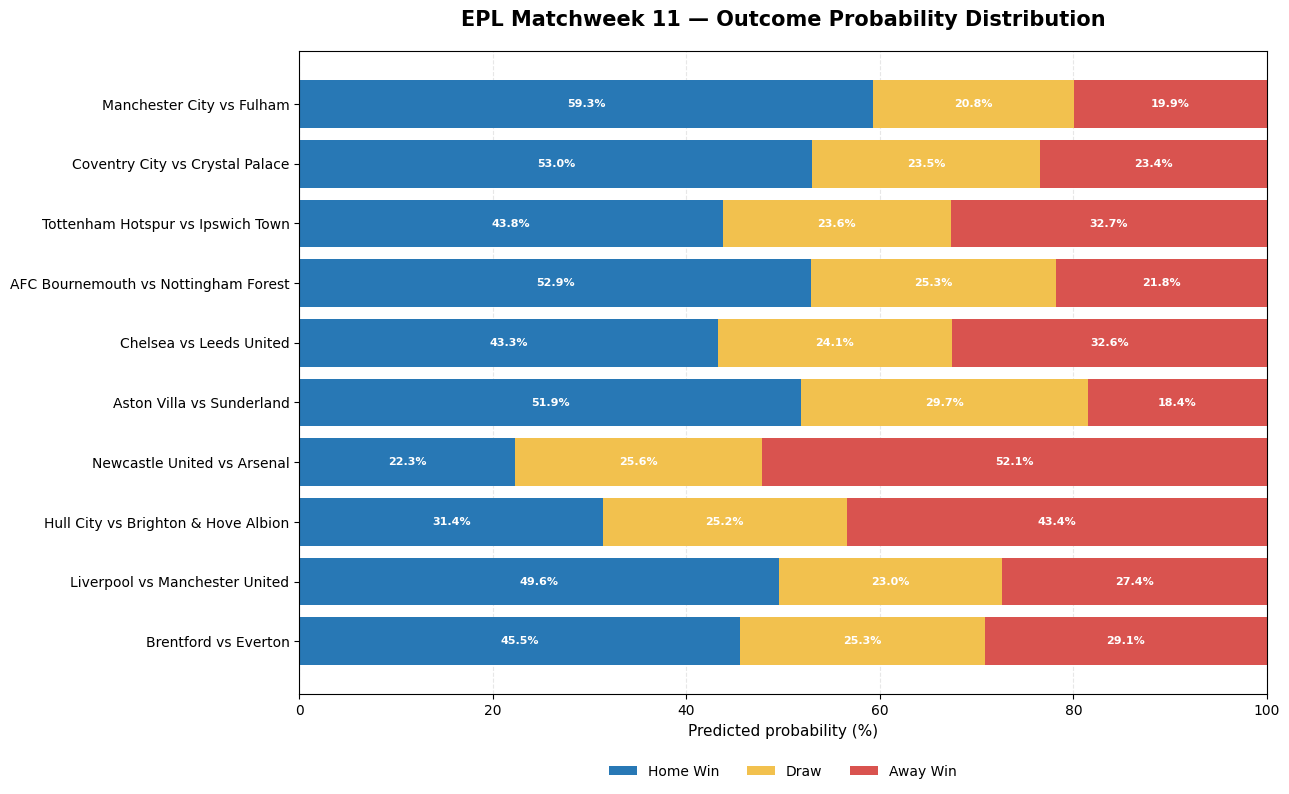

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare plotting data
plot_df = mw11_predictions.copy()

plot_df["Fixture"] = (
    plot_df["home_team_name"] + " vs " + plot_df["away_team_name"]
)

plot_df = plot_df.sort_values("Match Date")

home_probs = plot_df["Home Win Probability"].values
draw_probs = plot_df["Draw Probability"].values
away_probs = plot_df["Away Win Probability"].values

fixtures = plot_df["Fixture"].values

# Create figure
fig, ax = plt.subplots(figsize=(13, 8))

# Horizontal stacked bars
ax.barh(
    fixtures,
    home_probs,
    color="#2878B5",
    label="Home Win"
)

ax.barh(
    fixtures,
    draw_probs,
    left=home_probs,
    color="#F2C14E",
    label="Draw"
)

ax.barh(
    fixtures,
    away_probs,
    left=home_probs + draw_probs,
    color="#D9534F",
    label="Away Win"
)

# Add percentage labels
for i in range(len(plot_df)):

    segments = [
        (home_probs[i], 0),
        (draw_probs[i], home_probs[i]),
        (away_probs[i], home_probs[i] + draw_probs[i])
    ]

    for width, left in segments:

        if width >= 7:

            ax.text(
                left + width / 2,
                i,
                f"{width:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold",
                color="white" if width > 15 else "black"
            )

# Formatting
ax.set_xlabel("Predicted probability (%)", fontsize=11)
ax.set_title(
    "EPL Matchweek 11 — Outcome Probability Distribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlim(0, 100)
ax.invert_yaxis()

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

# Extract model coefficients

In [ ]:
# Extract Logistic Regression coefficients

logistic_model = final_mw11_model.named_steps["model"]

coefficient_df = pd.DataFrame(
    logistic_model.coef_,
    columns=mw11_feature_columns,
    index=logistic_model.classes_
)

# Display coefficients for each outcome
display(
    coefficient_df.T.sort_values(
        by="H",
        ascending=False
    ).rename(
        columns={
            "H": "Home Win",
            "D": "Draw",
            "A": "Away Win"
        }
    )
)

,Away Win,Draw,Home Win
elo_difference,-0.458569,-0.040287,0.498856
away_points_last5,-0.309632,0.050995,0.258637
away_goals_conceded_last5,-0.121292,0.025386,0.095906
home_points_last5,-0.302637,0.226904,0.075733
goals_scored_form_difference,-0.074209,0.009363,0.064846
win_rate_form_difference,0.043897,-0.095705,0.051808
home_goals_scored_last5,-0.001866,-0.048679,0.050545
away_cold_start,-0.036829,0.018684,0.018145
home_cold_start,0.056773,-0.048021,-0.008753
home_goals_conceded_last5,-0.052560,0.066385,-0.013825


# Logistic Regression coefficient heatmap

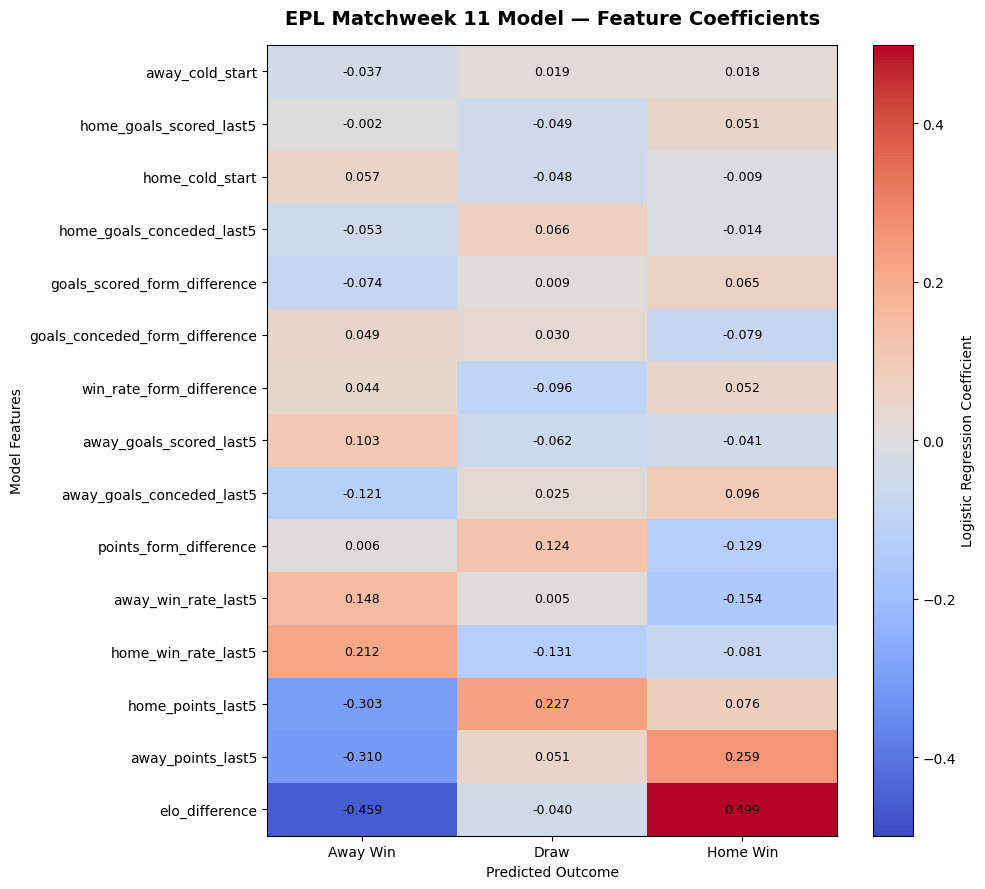

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare coefficient data
coef_heatmap = coefficient_df.T.copy()

coef_heatmap.columns = [
    "Away Win",
    "Draw",
    "Home Win"
]

# Sort features by their overall coefficient magnitude
coef_heatmap["Importance Magnitude"] = (
    coef_heatmap[
        ["Away Win", "Draw", "Home Win"]
    ].abs().max(axis=1)
)

coef_heatmap = coef_heatmap.sort_values(
    "Importance Magnitude",
    ascending=True
)

# Remove sorting helper from plotting data
plot_coefficients = coef_heatmap[
    ["Away Win", "Draw", "Home Win"]
]

# Symmetric color limits around zero
max_abs = np.abs(plot_coefficients.values).max()

fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(
    plot_coefficients.values,
    cmap="coolwarm",
    aspect="auto",
    vmin=-max_abs,
    vmax=max_abs
)

# Axis labels
ax.set_xticks(range(len(plot_coefficients.columns)))
ax.set_xticklabels(plot_coefficients.columns)

ax.set_yticks(range(len(plot_coefficients.index)))
ax.set_yticklabels(plot_coefficients.index)

# Annotate coefficient values
for i in range(plot_coefficients.shape[0]):
    for j in range(plot_coefficients.shape[1]):

        value = plot_coefficients.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=9,
            color="black"
        )

# Titles and formatting
ax.set_title(
    "EPL Matchweek 11 Model — Feature Coefficients",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Outcome")
ax.set_ylabel("Model Features")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Logistic Regression Coefficient")

plt.tight_layout()
plt.show()